# Habitat imaging for 1p/19q codeletion in IDH-mutant gliomas — audited rebuild (v3)

This notebook replaces `Habitat_features_iteration_2.ipynb`. It rebuilds the study around one pre-specified question and makes every step auditable: cohort construction, label provenance, habitat fitting inside cross-validation, composition-adjusted spatial metrics, a baseline ladder (M0–M5), paired statistics, cross-cohort testing and two null tests.

**How to read the outputs.** Sections 4–6 (cohort audit) and the metadata-only baselines run on the two official metadata files alone. Every cell that needs MRI volumes checks for them first. When they are missing, the cell prints `NOT EVALUATED` with the reason instead of producing numbers. Nothing in this notebook is filled in by hand: every number in a table or figure comes from code executed above it.

**Run modes** (set `GLIOMA_IMAGING_MODE` before starting, see section 3):

| Mode | What runs | Use |
| --- | --- | --- |
| `real` (default) | Cohort audit + all imaging sections against your NIfTI files | The study |
| `synthetic_smoke_test` | Cohort audit on the real metadata; imaging sections on small generated volumes with fake IDs | Software verification only. Every output is stamped `SYNTHETIC SMOKE TEST — NOT STUDY RESULTS`. |

## 1. Research question, hypotheses and the pre-specified primary comparison

**Question.** Among IDH-mutant diffuse gliomas, do MRI habitat composition and, specifically, the *spatial arrangement* of habitats carry information about 1p/19q codeletion beyond tumour volume, cohort effects and conventional whole-tumour radiomics?

**Clinical frame.** Under WHO CNS5, an IDH-mutant diffuse glioma is an oligodendroglioma if and only if it is 1p/19q-codeleted; otherwise it is an IDH-mutant astrocytoma ([Louis et al., 2021](https://doi.org/10.1093/neuonc/noab106)). The outcome here is therefore the astrocytoma-versus-oligodendroglioma distinction within IDH-mutant tumours.

**Hypotheses.**

- **H1 (primary, spatial arrangement).** Adding composition-adjusted spatial metrics to habitat composition improves discrimination: AUROC(M4) > AUROC(M3).
- **H2 (secondary, composition).** Habitat composition discriminates beyond simpler baselines: M3 versus M0 (cohort), M1 (volume + age + sex) and M2 (whole-tumour radiomics).
- **H3 (secondary, adjustment).** The habitat contribution persists after adjustment: M5 versus M1.
- **H4 (secondary, transport).** A model trained on one cohort discriminates in the other (leave-one-cohort-out).

**Pre-specified primary analysis (fixed before any imaging result was produced).**

| Item | Specification |
| --- | --- |
| Analysis set | UTSW IDH-mutant patients with a resolved 1p/19q label and ≥1 valid patch |
| Why UTSW only | The metadata audit (section 6) shows codeletion prevalence of about 45% at UTSW versus about 10% at UCSF, so cohort membership alone discriminates in pooled data. A single-cohort primary analysis removes that confound. This decision uses metadata only. |
| Comparison | ΔAUROC = AUROC(M4) − AUROC(M3), same outer folds |
| Estimator | L2-regularised logistic regression, C tuned by inner CV, class-balanced weights |
| Validation | Repeated stratified 5-fold CV (10 repeats); habitats refit inside every training fold |
| Inference | Nadeau–Bengio corrected resampled t-test on fold-level ΔAUROC (95% CI); stratified bootstrap CI as a check |
| Decision rule | H1 is supported only if the lower 95% bound of ΔAUROC is > 0 **and** the spatial-arrangement null test gives p < 0.05. Otherwise the result is reported as not supporting H1, whatever other comparisons show. |

**What this notebook does not claim.** An association between habitats and the label is not a predictive biomarker. Internal cross-validation is not external validation. Shannon entropy of habitat proportions is a function of composition alone, so it belongs to M3 here, not to the spatial set.

## 2. Dataset provenance, cohort compatibility and assumptions

| Item | UTSW-Glioma | UCSF-PDGM |
| --- | --- | --- |
| Reference | [Reddy et al., Scientific Data 2026](https://www.nature.com/articles/s41597-026-07274-4); TCIA collection UTSW-Glioma | [Calabrese et al., Radiology: AI 2022](https://doi.org/10.1148/ryai.220058); [TCIA collection page](https://wiki.cancerimagingarchive.net/x/54juBw) |
| Metadata file used here | `UTSW_Glioma_Metadata.tsv` (625 rows) | `UCSF-PDGM-metadata_v5.csv` (501 rows, includes follow-up scans) |
| Imaging period | 2006–2023 | 2015–2021 |
| Scanners | GE, Siemens, Philips, Hitachi, Toshiba; 0.3–3 T (per-patient in metadata) | Standardised 3 T protocol (dataset documentation; not per-patient in metadata) |
| Spatial normalisation | SRI24 atlas, 1 mm, FeTS | Each contrast registered to T2/FLAIR space, 1 mm, ANTs |
| Segmentation | FeTS automatic; a subset manually refined (per-patient flag) | BraTS 2021 ensemble, manually corrected and reviewed |
| IDH label | `IDH`: mutated / wild type / NA; method IHC or NGS | `IDH`: wildtype or a named IDH1/IDH2 variant or "mutated (NOS)" |
| 1p/19q label | `1p19Q CODEL`: co-deleted / non co-deleted / NA; NGS or PCR-LOH per the data descriptor | `1p/19q`: co-deletion / intact / relative co-deletion / unknown |
| Diagnosis | Histology terms (pre- and post-2016 nomenclature) | WHO 2021 integrated diagnosis |

**Assumptions made explicit (each is checked or flagged in code):**

1. Both cohorts are skull-stripped, so non-zero voxels define the brain for intensity normalisation.
2. The whole segmented abnormality (all non-zero labels) is the tumour region. In IDH-mutant tumours this is mostly non-enhancing T2/FLAIR abnormality.
3. The molecular 1p/19q field is the reference label in both cohorts, because UTSW diagnoses are histology-only. UCSF "relative co-deletion" is **not** treated as codeletion in the primary analysis. A sensitivity analysis resolves it using the WHO 2021 integrated diagnosis.
4. Histological grade is post-operative pathology and is not used as a predictor.
5. Pooling is not assumed to be valid. Section 6 tests it; the primary analysis does not depend on it.

**Harmonisation.** ComBat-style harmonisation assumes the site effect is a location-scale shift and needs adequate patients per batch and balanced biological covariates ([Orlhac et al., 2022](https://jnm.snmjournals.org/content/63/2/172)). Here the batch (cohort) is strongly associated with the outcome, so harmonising without the outcome as a covariate would remove real signal, and with it the transform cannot be applied to unlabelled test patients. Harmonisation is therefore **off** by default; a training-only per-cohort standardisation is available as a sensitivity option (`CONFIG["harmonisation"]`).

## 3. Configuration and environment

All settings live in `CONFIG`. Paths come from environment variables so that no personal path is hard-coded:

- `GLIOMA_DATA_ROOT` — folder holding the two metadata files and the imaging folders (default `./data`).
- `GLIOMA_OUTPUT_DIR` — where tables, figures, caches and the manifest are written (default `./outputs`).
- `GLIOMA_IMAGING_MODE` — `real` or `synthetic_smoke_test`.

On Google Colab, mount Drive yourself and point `GLIOMA_DATA_ROOT` at the folder, e.g. `os.environ["GLIOMA_DATA_ROOT"] = "/content/drive/MyDrive"` before running this cell. The default imaging layout below is the one your original notebook created (cell 13 of iteration 2: `UTSW_processed/<id>/…` and `UCSF/images/<id>/…`); change `CONFIG["imaging"]` if yours differs.

Pinned dependencies are listed in `requirements.txt`. PyRadiomics is pinned to a specific commit because the PyPI 3.1.0 source release failed to build in the Python 3.13 environment used to test this notebook.

In [1]:
import os, sys, json, math, hashlib, logging, platform, time, warnings, itertools, re, shutil, importlib
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.ndimage import distance_transform_edt
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, brier_score_loss,
                             confusion_matrix, adjusted_rand_score, silhouette_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S")
log = logging.getLogger("habitat_v3")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 80)

# Optional imaging libraries: the cohort audit runs without them.
try:
    import SimpleITK as sitk
    HAVE_SITK = True
except ImportError:
    HAVE_SITK = False
try:
    from radiomics import featureextractor
    import radiomics as _radiomics
    logging.getLogger("radiomics").setLevel(logging.ERROR)
    HAVE_RADIOMICS = True
except ImportError:
    HAVE_RADIOMICS = False
try:
    from joblib import Parallel, delayed
    HAVE_JOBLIB = True
except ImportError:
    HAVE_JOBLIB = False

CONFIG = {
    "seed": 20261012,
    "data_root": Path(os.environ.get("GLIOMA_DATA_ROOT", "data")).expanduser(),
    "output_dir": Path(os.environ.get("GLIOMA_OUTPUT_DIR", "outputs")).expanduser(),
    "imaging_mode": os.environ.get("GLIOMA_IMAGING_MODE", "real"),
    "utsw_metadata": "UTSW_Glioma_Metadata.tsv",
    "ucsf_metadata": "UCSF-PDGM-metadata_v5.csv",
    # Imaging layout (from iteration-2 cell 13). {pid} = canonical ID; UCSF also tries 3/4-digit variants.
    "imaging": {
        "UTSW": {"root": "UTSW_processed",
                 "files": {"T1": "T1.nii.gz", "T1CE": "T1_GD.nii.gz", "T2": "T2.nii.gz",
                           "FLAIR": "FLAIR.nii.gz", "SEG": "segmentation.nii.gz"}},
        "UCSF": {"root": "UCSF/images",
                 "files": {"T1": "T1.nii.gz", "T1CE": "T1_GD.nii.gz", "T2": "T2.nii.gz",
                           "FLAIR": "FLAIR.nii.gz", "SEG": "seg_mask.nii.gz"}},
    },
    "modalities": ["T1", "T1CE", "T2", "FLAIR"],
    "tumour_labels": None,              # None = every non-zero segmentation label (whole abnormality)
    "n4_bias_correction": True,
    "target_spacing": (1.0, 1.0, 1.0),
    "patch_size": 32, "patch_stride": 16, "min_tumour_fraction": 0.25,
    "bin_width": 0.25,
    "texture_classes": ["firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"],
    "n_jobs": max(1, (os.cpu_count() or 2) - 1),
    "habitat": {"pca_variance": 0.95, "k_grid": [3, 4, 5, 6, 7, 8], "stability_bootstraps": 10,
                "kmeans_n_init": 10, "selection_n_init": 3, "min_habitat_share": 0.02,
                "stability_tolerance": 0.02, "fixed_k": None, "silhouette_sample": 3000},
    "spatial": {"min_patches": 4, "n_inner_null": 200},
    "cv": {"n_splits": 5, "n_repeats": 10, "inner_splits": 5},
    "logreg_C_grid": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0],
    "rf": {"n_estimators": 500, "max_depth": 4, "min_samples_leaf": 5, "class_weight": "balanced_subsample"},
    "n_bootstrap": 2000,
    "n_label_permutations": 200,
    "n_spatial_null": 100,
    "min_train_events_loco": 20,
    "k_sensitivity": [4, 5, 6, 7, 8],
    "harmonisation": None,              # None | "per_cohort_zscore" (sensitivity only)
    "primary": {"analysis_set": "UTSW", "test": "M4", "reference": "M3", "estimator": "logreg"},
    "colors": {"non-codeleted": "#2a78d6", "codeleted": "#eb6834", "UTSW": "#6250d6", "UCSF": "#1baf7a",
               "models": ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]},
}

SMOKE = CONFIG["imaging_mode"] == "synthetic_smoke_test"
assert CONFIG["imaging_mode"] in {"real", "synthetic_smoke_test"}, CONFIG["imaging_mode"]
if SMOKE:
    # Small, fast settings that exercise every code path. They are NOT study settings.
    CONFIG.update({"patch_size": 16, "patch_stride": 8, "n4_bias_correction": False,
                   "n_bootstrap": 200, "n_label_permutations": 10, "n_spatial_null": 5,
                   "k_sensitivity": [3, 4], "n_jobs": min(4, CONFIG["n_jobs"])})
    CONFIG["cv"] = {"n_splits": 3, "n_repeats": 2, "inner_splits": 3}
    CONFIG["habitat"].update({"k_grid": [2, 3, 4], "stability_bootstraps": 3, "kmeans_n_init": 4, "selection_n_init": 2})
    CONFIG["spatial"]["n_inner_null"] = 50
    CONFIG["min_train_events_loco"] = 5

OUT = CONFIG["output_dir"]
for sub in ["tables", "figures", "cache", "features"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

def banner():
    if SMOKE:
        print("=" * 78 + "\nSYNTHETIC SMOKE TEST — NOT STUDY RESULTS\n" + "=" * 78)

def save_table(df, name):
    path = OUT / "tables" / f"{name}.csv"
    df.to_csv(path, index=True)
    return path

def save_fig(fig, name):
    path = OUT / "figures" / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path

def pkg_version(name):
    try:
        mod = importlib.import_module(name)
        return getattr(mod, "__version__", None) or (mod.Version_VersionString() if name == "SimpleITK" else "unknown")
    except Exception:
        return "not installed"

ENV = {"python": platform.python_version(), "platform": platform.platform(),
       **{p: pkg_version(p) for p in ["numpy", "pandas", "scipy", "sklearn", "matplotlib", "SimpleITK", "radiomics", "joblib"]}}
print(json.dumps(ENV, indent=1))
print("Imaging mode:", CONFIG["imaging_mode"], "| data root:", CONFIG["data_root"].resolve(), "| outputs:", OUT.resolve())
banner()

{
 "python": "3.13.16",
 "platform": "Linux-6.18.44-fc-v114-x86_64-with-glibc2.39",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scipy": "1.18.1",
 "sklearn": "1.9.1",
 "matplotlib": "3.11.2",
 "SimpleITK": "2.5.6",
 "radiomics": "3.1.1.dev111+g8ed579383",
 "joblib": "1.6.0"
}
Imaging mode: real | data root: /home/claude/work/data | outputs: /home/claude/work/outputs_real


In [2]:
# Plot style: one colour per class / cohort / model, fixed order, used identically in every figure.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "font.size": 10, "legend.frameon": False, "lines.linewidth": 2})
CLASS_COL = {0: CONFIG["colors"]["non-codeleted"], 1: CONFIG["colors"]["codeleted"]}
CLASS_NAME = {0: "1p/19q non-codeleted", 1: "1p/19q codeleted"}
COHORT_COL = {"UTSW": CONFIG["colors"]["UTSW"], "UCSF": CONFIG["colors"]["UCSF"]}
# Colour follows the model, never its position in a list; "+cohort" variants reuse the base colour with a dashed line.
MODEL_ORDER = ["M0", "M1_clin", "M1", "M2", "M3", "M4", "M5"]
MODEL_COL = dict(zip(MODEL_ORDER, CONFIG["colors"]["models"]))
def model_style(m):
    return {"color": MODEL_COL[m.replace("+cohort", "")], "ls": "--" if m.endswith("+cohort") else "-"}

## 4. Cohort ingestion and patient-level integrity checks

Both metadata files are read as text with **no automatic missing-value conversion**, so that strings such as `NA`, `unknown` and `Not Reported` are mapped explicitly rather than silently. Every categorical field goes through a strict mapping: an unexpected value stops the notebook instead of becoming a default.

Checks in this section:

1. Expected columns are present.
2. Source IDs are unique within each file.
3. IDs parse to a canonical patient ID. UCSF-PDGM v5 contains follow-up scans (`…_FU###d`) of patients who also have a baseline row; these are detected, compared with the baseline row for conflicts, and removed so each patient appears once.
4. No canonical ID appears in both cohorts.
5. Missingness of every harmonised field, by cohort.

In [3]:
UTSW_REQUIRED = ["Subject ID", "Sex at birth", "Age at Imaging", "Tumor Type", "Tumor Grade", "IDH", "IDH_Testing Method",
                 "1p19Q CODEL", "Operation Status", "T1", "T1GD", "T2", "T2FLAIR", "Scanner Make", "Scanner Model",
                 "Scanner Strength", "Manually Refined Segmentation"]
UCSF_REQUIRED = ["ID", "Sex", "Age at MRI", "WHO CNS Grade", "Final pathologic diagnosis (WHO 2021)", "1p/19q", "IDH",
                 "Biopsy prior to imaging", "BraTS21 ID", "BraTS21 Segmentation Cohort"]

# Strict value maps. Anything not listed raises an error.
UTSW_IDH_MAP = {"mutated": "mutant", "wild type": "wildtype", "NA": "unknown"}
UTSW_CODEL_MAP = {"co-deleted": "codeleted", "non co-deleted": "non-codeleted", "NA": "unknown"}
UCSF_CODEL_MAP = {"co-deletion": "codeleted", "intact": "non-codeleted",
                  "relative co-deletion": "relative_codeletion", "unknown": "unknown"}
SEX_MAP = {"M": "M", "F": "F"}
YESNO_MAP = {"Yes": True, "No": False}

def strict_map(series, mapping, field):
    values = series.astype(str).str.strip()
    unknown = sorted(set(values) - set(mapping))
    if unknown:
        raise ValueError(f"{field}: unmapped values {unknown}. Add them to the explicit map after checking their meaning.")
    return values.map(mapping)

def map_ucsf_idh(value):
    v = str(value).strip()
    if v.lower() == "wildtype":
        return "wildtype"
    if re.match(r"^(IDH[12] p\.\S+|mutated \(NOS\))$", v):
        return "mutant"
    if v.lower() in {"unknown", ""}:
        return "unknown"
    raise ValueError(f"UCSF IDH: unmapped value {v!r}")

def to_float(series, missing=("NA", "Not Reported", "unknown", "")):
    s = series.astype(str).str.strip()
    return pd.to_numeric(s.where(~s.isin(missing)), errors="raise")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def read_text_table(path, sep):
    if not Path(path).is_file():
        raise FileNotFoundError(f"Metadata file not found: {path}. Set GLIOMA_DATA_ROOT or CONFIG paths.")
    return pd.read_csv(path, sep=sep, dtype=str, keep_default_na=False, na_filter=False)

def load_utsw(path):
    raw = read_text_table(path, "\t")
    missing = [c for c in UTSW_REQUIRED if c not in raw.columns]
    assert not missing, f"UTSW metadata missing columns: {missing}"
    ids = raw["Subject ID"].str.strip()
    assert ids.str.match(r"^BT\d{4}$").all(), "Unexpected UTSW Subject ID format"
    out = pd.DataFrame({
        "cohort": "UTSW",
        "source_id": ids,
        "patient_id": "UTSW-" + ids,
        "is_followup": False,
        "age": to_float(raw["Age at Imaging"]),
        "sex": strict_map(raw["Sex at birth"], SEX_MAP, "UTSW sex"),
        "grade": to_float(raw["Tumor Grade"]),
        "diagnosis": raw["Tumor Type"].str.strip(),
        "diagnosis_system": "histology (mixed eras)",
        "idh_raw": raw["IDH"].str.strip(),
        "idh_status": strict_map(raw["IDH"], UTSW_IDH_MAP, "UTSW IDH"),
        "idh_method": raw["IDH_Testing Method"].str.strip().replace({"NA": np.nan}),
        "codel_raw": raw["1p19Q CODEL"].str.strip(),
        "codel_status": strict_map(raw["1p19Q CODEL"], UTSW_CODEL_MAP, "UTSW 1p/19q"),
        "operation_status": raw["Operation Status"].str.strip(),
        "modalities_listed": (raw[["T1", "T1GD", "T2", "T2FLAIR"]] == "Available").all(axis=1),
        "scanner_make": raw["Scanner Make"].str.strip().replace({"Not Reported": np.nan}),
        "scanner_model": raw["Scanner Model"].str.strip().replace({"Not Reported": np.nan}),
        "field_strength_T": to_float(raw["Scanner Strength"]).round(2),
        "seg_provenance": np.where(strict_map(raw["Manually Refined Segmentation"], YESNO_MAP, "UTSW seg").astype(bool),
                                   "FeTS + manual refinement", "FeTS automatic"),
        "biopsy_prior_to_imaging": np.nan,
        "brats21_id": np.nan,
    })
    return raw, out

UCSF_ID_RE = re.compile(r"^UCSF-PDGM-(\d{3,4})(?:_FU(\d+)d)?$")

def load_ucsf(path):
    raw = read_text_table(path, ",")
    missing = [c for c in UCSF_REQUIRED if c not in raw.columns]
    assert not missing, f"UCSF metadata missing columns: {missing}"
    parsed = raw["ID"].str.strip().str.extract(UCSF_ID_RE)
    bad = raw.loc[parsed[0].isna(), "ID"].tolist()
    assert not bad, f"Unparseable UCSF IDs: {bad}"
    num = parsed[0].astype(int)
    out = pd.DataFrame({
        "cohort": "UCSF",
        "source_id": raw["ID"].str.strip(),
        "patient_id": "UCSF-PDGM-" + num.map(lambda n: f"{n:04d}"),
        "is_followup": parsed[1].notna(),
        "followup_days": pd.to_numeric(parsed[1]),
        "age": to_float(raw["Age at MRI"]),
        "sex": strict_map(raw["Sex"], SEX_MAP, "UCSF sex"),
        "grade": to_float(raw["WHO CNS Grade"]),
        "diagnosis": raw["Final pathologic diagnosis (WHO 2021)"].str.strip(),
        "diagnosis_system": "WHO 2021 integrated",
        "idh_raw": raw["IDH"].str.strip(),
        "idh_status": raw["IDH"].map(map_ucsf_idh),
        "idh_method": np.nan,
        "codel_raw": raw["1p/19q"].str.strip(),
        "codel_status": strict_map(raw["1p/19q"], UCSF_CODEL_MAP, "UCSF 1p/19q"),
        "operation_status": "PRE (dataset: preoperative)",
        "modalities_listed": True,   # UCSF-PDGM distributes all four structural contrasts; verified on disk in section 7
        "scanner_make": np.nan, "scanner_model": np.nan,
        "field_strength_T": np.nan,  # not per-patient in metadata; dataset documentation: standardised 3 T protocol
        "seg_provenance": "BraTS21 ensemble + manual correction",
        "biopsy_prior_to_imaging": strict_map(raw["Biopsy prior to imaging"], YESNO_MAP, "UCSF biopsy").astype(bool),
        "brats21_id": raw["BraTS21 ID"].str.strip().replace({"": np.nan}),
    })
    return raw, out

utsw_path = CONFIG["data_root"] / CONFIG["utsw_metadata"]
ucsf_path = CONFIG["data_root"] / CONFIG["ucsf_metadata"]
utsw_raw, utsw = load_utsw(utsw_path)
ucsf_raw, ucsf = load_ucsf(ucsf_path)
INPUT_HASHES = {str(utsw_path.name): sha256(utsw_path), str(ucsf_path.name): sha256(ucsf_path)}
print(f"UTSW rows: {len(utsw_raw)} | UCSF rows: {len(ucsf_raw)}")
print("SHA-256:", json.dumps(INPUT_HASHES, indent=1))

UTSW rows: 625 | UCSF rows: 501
SHA-256: {
 "UTSW_Glioma_Metadata.tsv": "f7ff889fa7d197b2f589695d3e7ea8a2d1d198c4f9c0044fc71898a08aa24ed0",
 "UCSF-PDGM-metadata_v5.csv": "afc1c23a0eb0597b56e603741e72f2308b4860281187cd3808e05b7a0116fd78"
}


In [4]:
CHECKS = OrderedDict()   # every verification is recorded here and summarised in section 18

def record_check(name, passed, detail="", status=None):
    status = status or ("PASS" if passed else "FAIL")
    CHECKS[name] = {"status": status, "detail": detail}
    print(f"{status} {name}" + (f" — {detail}" if detail else ""))

# 1. Unique source IDs within each file
record_check("UTSW source IDs unique", utsw["source_id"].is_unique, f"{utsw['source_id'].nunique()} unique of {len(utsw)}")
record_check("UCSF source IDs unique", ucsf["source_id"].is_unique, f"{ucsf['source_id'].nunique()} unique of {len(ucsf)}")

# 2. UCSF follow-up scans: compare with the baseline row of the same patient
fu = ucsf[ucsf["is_followup"]]
compare_cols = ["age", "sex", "idh_status", "codel_status", "diagnosis", "grade"]
fu_rows = []
for _, r in fu.iterrows():
    base = ucsf[(ucsf["patient_id"] == r["patient_id"]) & (~ucsf["is_followup"])]
    conflicts = [] if len(base) != 1 else [c for c in compare_cols if str(base.iloc[0][c]) != str(r[c])]
    fu_rows.append({"followup_source_id": r["source_id"], "patient_id": r["patient_id"],
                    "baseline_rows": len(base), "baseline_source_id": base["source_id"].iloc[0] if len(base) else None,
                    "idh_status": r["idh_status"], "conflicting_fields": ", ".join(conflicts) or "none"})
followup_table = pd.DataFrame(fu_rows)
print("\nUCSF follow-up scans detected:")
display(followup_table)
record_check("Every UCSF follow-up has exactly one baseline row", bool((followup_table["baseline_rows"] == 1).all()) if len(fu) else True,
             f"{len(fu)} follow-up rows")

# 3. Keep one row per patient: the baseline (non-follow-up) scan
ucsf_patients = ucsf[~ucsf["is_followup"]].copy()
record_check("UCSF canonical patient IDs unique after removing follow-ups", ucsf_patients["patient_id"].is_unique,
             f"{ucsf_patients['patient_id'].nunique()} patients")
cohort_all = pd.concat([utsw, ucsf_patients], ignore_index=True)
record_check("No patient ID shared across cohorts", cohort_all["patient_id"].is_unique)

# 4. Missingness of harmonised fields by cohort (NaN or explicit 'unknown')
fields = ["age", "sex", "grade", "idh_status", "idh_method", "codel_status", "scanner_make", "field_strength_T",
          "seg_provenance", "biopsy_prior_to_imaging"]
miss = {}
for coh, g in cohort_all.groupby("cohort"):
    miss[coh] = {f: int(g[f].isna().sum() + (g[f].astype(str) == "unknown").sum()) for f in fields}
missingness = pd.DataFrame(miss)
missingness.index.name = "field (missing or 'unknown')"
display(missingness)
save_table(missingness, "04_missingness_by_cohort")
save_table(followup_table, "04_ucsf_followup_scans")

PASS UTSW source IDs unique — 625 unique of 625
PASS UCSF source IDs unique — 501 unique of 501

UCSF follow-up scans detected:


,followup_source_id,patient_id,baseline_rows,baseline_source_id,idh_status,conflicting_fields
0,UCSF-PDGM-0429_FU003d,UCSF-PDGM-0429,1,UCSF-PDGM-429,wildtype,none
1,UCSF-PDGM-0396_FU175d,UCSF-PDGM-0396,1,UCSF-PDGM-396,wildtype,none
2,UCSF-PDGM-0409_FU001d,UCSF-PDGM-0409,1,UCSF-PDGM-409,wildtype,none
3,UCSF-PDGM-0431_FU001d,UCSF-PDGM-0431,1,UCSF-PDGM-431,wildtype,none
4,UCSF-PDGM-0391_FU016d,UCSF-PDGM-0391,1,UCSF-PDGM-391,wildtype,none
5,UCSF-PDGM-0433_FU007d,UCSF-PDGM-0433,1,UCSF-PDGM-433,wildtype,none


PASS Every UCSF follow-up has exactly one baseline row — 6 follow-up rows
PASS UCSF canonical patient IDs unique after removing follow-ups — 495 patients
PASS No patient ID shared across cohorts


,UCSF,UTSW
field (missing or 'unknown'),,
age,0,0
sex,0,0
grade,0,7
idh_status,0,3
idh_method,495,3
codel_status,91,290
scanner_make,495,28
field_strength_T,495,28
seg_provenance,0,0


PosixPath('/home/claude/work/outputs_real/tables/04_ucsf_followup_scans.csv')

## 5. IDH and 1p/19q eligibility, label validation and patient flow

Eligibility is applied step by step and every step is counted, by cohort and by label status. The **primary label** is the molecular 1p/19q field:

| Raw value | UTSW | UCSF | Primary analysis |
| --- | --- | --- | --- |
| codeleted | `co-deleted` | `co-deletion` | label 1 |
| non-codeleted | `non co-deleted` | `intact` | label 0 |
| relative co-deletion | — | `relative co-deletion` | **excluded** (ambiguous; resolved only in a sensitivity analysis) |
| unknown | `NA` | `unknown` | excluded |

Label–diagnosis discordances are flagged, not silently corrected. UTSW diagnoses are histology terms from several eras, so a histological "oligodendroglioma" with intact 1p/19q is recorded as a discordance rather than relabelled.

In [5]:
def label_from_status(s):
    return {"codeleted": 1.0, "non-codeleted": 0.0}.get(s, np.nan)

cohort_all["label"] = cohort_all["codel_status"].map(label_from_status)

# Discordance and context flags
dx = cohort_all["diagnosis"].str.upper()
flags = pd.DataFrame(index=cohort_all.index)
is_utsw, is_ucsf = cohort_all["cohort"].eq("UTSW"), cohort_all["cohort"].eq("UCSF")
flags["histology_oligodendroglioma_but_intact"] = is_utsw & dx.str.startswith("OLIGODENDROGLIOMA") & cohort_all["codel_status"].eq("non-codeleted")
flags["histology_astrocytoma_but_codeleted"] = is_utsw & dx.str.startswith("ASTROCYTOMA") & cohort_all["codel_status"].eq("codeleted")
flags["histology_oligoastrocytoma"] = is_utsw & dx.str.startswith("OLIGOASTROCYTOMA")
flags["histology_glioblastoma_idh_mutant"] = is_utsw & dx.eq("GLIOBLASTOMA") & cohort_all["idh_status"].eq("mutant")
flags["grade4_codeleted"] = cohort_all["grade"].eq(4) & cohort_all["codel_status"].eq("codeleted")
flags["who2021_oligodendroglioma_label_not_codeleted"] = is_ucsf & dx.str.startswith("OLIGODENDROGLIOMA") & ~cohort_all["codel_status"].eq("codeleted")
flags["who2021_astrocytoma_label_codeleted"] = is_ucsf & dx.str.startswith("ASTROCYTOMA, IDH-MUTANT") & cohort_all["codel_status"].isin(["codeleted", "relative_codeletion"])
flags["ucsf_relative_codeletion"] = cohort_all["codel_status"].eq("relative_codeletion")
flags["ucsf_biopsy_prior_to_imaging"] = cohort_all["biopsy_prior_to_imaging"].eq(True)
flags["idh_wildtype_codeleted"] = cohort_all["idh_status"].eq("wildtype") & cohort_all["codel_status"].eq("codeleted")
cohort_all = pd.concat([cohort_all, flags.add_prefix("flag_")], axis=1)

idh_mut = cohort_all["idh_status"].eq("mutant")
flag_summary = (cohort_all.loc[idh_mut, ["cohort"] + [c for c in cohort_all if c.startswith("flag_")]]
                .groupby("cohort").sum().T)
flag_summary.index = flag_summary.index.str.replace("flag_", "", regex=False)
print("Flags among IDH-mutant patients (counts):")
display(flag_summary)
save_table(flag_summary, "05_flags_idh_mutant")
record_check("No IDH-wildtype tumour labelled codeleted", int(cohort_all["flag_idh_wildtype_codeleted"].sum()) == 0,
             f"{int(cohort_all['flag_idh_wildtype_codeleted'].sum())} cases")
record_check("No grade-4 tumour labelled codeleted", int(cohort_all["flag_grade4_codeleted"].sum()) == 0,
             f"{int(cohort_all['flag_grade4_codeleted'].sum())} cases")

Flags among IDH-mutant patients (counts):


cohort,UCSF,UTSW
histology_oligodendroglioma_but_intact,0,4
histology_astrocytoma_but_codeleted,0,2
histology_oligoastrocytoma,0,26
histology_glioblastoma_idh_mutant,0,20
grade4_codeleted,0,0
who2021_oligodendroglioma_label_not_codeleted,4,0
who2021_astrocytoma_label_codeleted,2,0
ucsf_relative_codeletion,6,0
ucsf_biopsy_prior_to_imaging,13,0
idh_wildtype_codeleted,0,0


PASS No IDH-wildtype tumour labelled codeleted — 0 cases
PASS No grade-4 tumour labelled codeleted — 0 cases


In [6]:
def flow_counts(df, step):
    rows = []
    for coh in ["UTSW", "UCSF"]:
        g = df[df["cohort"] == coh]
        rows.append({"step": step, "cohort": coh, "n": len(g),
                     "codeleted": int((g["codel_status"] == "codeleted").sum()),
                     "non-codeleted": int((g["codel_status"] == "non-codeleted").sum()),
                     "relative": int((g["codel_status"] == "relative_codeletion").sum()),
                     "unknown": int((g["codel_status"] == "unknown").sum())})
    return rows

flow = []
all_rows = pd.concat([utsw, ucsf], ignore_index=True)
flow += flow_counts(all_rows, "S0 rows in metadata files")
flow += flow_counts(cohort_all, "S1 unique patients (UCSF follow-up scans removed)")
s2 = cohort_all[cohort_all["idh_status"] != "unknown"]
flow += flow_counts(s2, "S2 IDH status known")
s3 = s2[s2["idh_status"] == "mutant"]
flow += flow_counts(s3, "S3 IDH-mutant")
s4 = s3[s3["codel_status"].isin(["codeleted", "non-codeleted"])]
flow += flow_counts(s4, "S4 1p/19q resolved (primary label)")
flow_df = pd.DataFrame(flow)
display(flow_df.set_index(["step", "cohort"]))

eligible = s4.copy().reset_index(drop=True)
eligible["label"] = eligible["label"].astype(int)
assert eligible["patient_id"].is_unique
assert set(eligible["label"].unique()) <= {0, 1}
assert eligible["idh_status"].eq("mutant").all()
record_check("Eligible cohort is IDH-mutant only", True, f"{len(eligible)} patients")

# Label-sensitivity sets (defined now, used in section 15)
sens = s3.copy()
who_label = np.where(sens["diagnosis"].str.startswith("Oligodendroglioma"), 1.0,
                     np.where(sens["diagnosis"].str.startswith("Astrocytoma, IDH-mutant"), 0.0, np.nan))
sens["label_who2021_resolved"] = np.where(sens["cohort"].eq("UCSF") & sens["codel_status"].isin(["relative_codeletion", "unknown"]),
                                          who_label, sens["label"])
LABEL_SETS = {
    "primary": eligible["patient_id"].tolist(),
    "ucsf_relative_resolved_by_who2021": sens.loc[sens["label_who2021_resolved"].notna(), "patient_id"].tolist(),
    "exclude_histology_discordant": eligible.loc[~(eligible["flag_histology_oligodendroglioma_but_intact"] |
                                                   eligible["flag_histology_astrocytoma_but_codeleted"]), "patient_id"].tolist(),
    "exclude_grade4": eligible.loc[~eligible["grade"].eq(4), "patient_id"].tolist(),
    "exclude_ucsf_biopsy_prior": eligible.loc[~eligible["biopsy_prior_to_imaging"].eq(True), "patient_id"].tolist(),
}
SENS_LABELS = sens.set_index("patient_id")["label_who2021_resolved"]
print({k: len(v) for k, v in LABEL_SETS.items()})
save_table(flow_df, "05_patient_flow_metadata")

n  codeleted  non-codeleted  relative  unknown
step                                              cohort                                                  
S0 rows in metadata files                         UTSW    625         63            272         0      290
                                                  UCSF    501          9            395         6       91
S1 unique patients (UCSF follow-up scans removed) UTSW    625         63            272         0      290
                                                  UCSF    495          9            389         6       91
S2 IDH status known                               UTSW    622         63            272         0      287
                                                  UCSF    495          9            389         6       91
S3 IDH-mutant                                     UTSW    176         63             77         0       36
                                                  UCSF    103          9             84         6        4
S4 1p/19q resolved (primary label)                UTSW    140         63             77         0        0
                                                  UCSF     93          9             84         0        0

PASS Eligible cohort is IDH-mutant only — 233 patients
{'primary': 233, 'ucsf_relative_resolved_by_who2021': 243, 'exclude_histology_discordant': 227, 'exclude_grade4': 197, 'exclude_ucsf_biopsy_prior': 220}


PosixPath('/home/claude/work/outputs_real/tables/05_patient_flow_metadata.csv')

### 5.1 Can the original iteration-2 cohort be reconstructed?

Iteration 2 reported 156 labelled patients (46 codeleted, 110 non-codeleted) but built them from intermediate files (`labels.csv`, `updated_utsw_metadata.tsv`) that are not part of the notebook. Its label normaliser also did not recognise the raw strings in either official file (`non co-deleted`, `co-deletion`, `relative co-deletion`), so the labels must have been recoded upstream.

The cell below tests one candidate filter. A match in counts is **consistent with**, not proof of, how the original cohort was built. It also reports how well cohort membership alone separates the classes in that candidate cohort, which is the floor the iteration-2 AUROC of 0.76–0.78 should be compared with. (Iteration 2 then dropped 24 patients with no or few patches, so its final 132-patient set differs slightly.)

In [7]:
cand = eligible[(eligible["cohort"].eq("UTSW") & eligible["seg_provenance"].eq("FeTS + manual refinement")) |
                (eligible["cohort"].eq("UCSF") & ~eligible["biopsy_prior_to_imaging"].eq(True))]
cand_counts = cand.groupby(["cohort", "label"]).size().unstack(fill_value=0)
display(cand_counts)
n_pos, n_neg = int(cand["label"].sum()), int((1 - cand["label"]).sum())
match = (len(cand), n_pos, n_neg) == (156, 46, 110)
print(f"Candidate filter (UTSW manually refined segmentations + UCSF without prior biopsy): "
      f"{len(cand)} patients, {n_pos} codeleted / {n_neg} non-codeleted -> "
      f"{'MATCHES' if match else 'does not match'} iteration 2 (156: 46/110).")
# How much of the iteration-2 AUROC (0.76-0.78) could cohort membership alone explain in that cohort?
cand_site_auc = roc_auc_score(cand["label"], cand["cohort"].eq("UTSW").astype(float))
print(f"In this candidate cohort, cohort membership alone gives AUROC {cand_site_auc:.3f} "
      f"(codeletion prevalence UTSW {cand.loc[cand.cohort.eq('UTSW'), 'label'].mean():.2f}, "
      f"UCSF {cand.loc[cand.cohort.eq('UCSF'), 'label'].mean():.2f}).")
ORIGINAL_COHORT_HYPOTHESIS = {"filter": "UTSW manual refinement == Yes; UCSF biopsy prior == No; IDH-mutant; label resolved",
                              "n": len(cand), "codeleted": n_pos, "non_codeleted": n_neg, "matches_iteration2_counts": bool(match),
                              "cohort_only_auroc": cand_site_auc}

label,0,1
cohort,,
UCSF,71,9
UTSW,39,37


Candidate filter (UTSW manually refined segmentations + UCSF without prior biopsy): 156 patients, 46 codeleted / 110 non-codeleted -> MATCHES iteration 2 (156: 46/110).
In this candidate cohort, cohort membership alone gives AUROC 0.725 (codeletion prevalence UTSW 0.49, UCSF 0.11).


## 6. Exploratory analysis and cohort audit

This section answers three questions before any imaging is touched:

1. Do the cohorts differ in outcome prevalence, age, sex, grade and acquisition?
2. How much can **cohort membership alone** predict the label in pooled data? That number is the floor any pooled imaging model must beat.
3. Which clinical variables are available, reliable and pre-operative (eligible for M1)?

The statistical helpers defined first are reused in every later section, so that confidence intervals and effect sizes are computed one way throughout.

In [8]:
# ---------- statistical helpers used throughout ----------
def wilson_ci(k, n, alpha=0.05):
    if n == 0:
        return (np.nan, np.nan)
    z = stats.norm.ppf(1 - alpha / 2)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centre - half, centre + half)

def stratified_bootstrap_indices(y, n_boot, rng):
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    for _ in range(n_boot):
        yield np.concatenate([rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)])

def auc_with_ci(y, score, n_boot=None, seed=0):
    y = np.asarray(y).astype(int); score = np.asarray(score, float)
    n_boot = n_boot or CONFIG["n_bootstrap"]
    if len(np.unique(y)) < 2:
        return {"auc": np.nan, "lo": np.nan, "hi": np.nan, "n": len(y), "n_pos": int(y.sum())}
    auc = roc_auc_score(y, score)
    rng = np.random.default_rng(seed)
    boots = [roc_auc_score(y[i], score[i]) for i in stratified_bootstrap_indices(y, n_boot, rng)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"auc": auc, "lo": lo, "hi": hi, "n": len(y), "n_pos": int(y.sum())}

def auprc_with_ci(y, score, n_boot=None, seed=0):
    y = np.asarray(y).astype(int); score = np.asarray(score, float)
    n_boot = n_boot or CONFIG["n_bootstrap"]
    ap = average_precision_score(y, score)
    rng = np.random.default_rng(seed)
    boots = [average_precision_score(y[i], score[i]) for i in stratified_bootstrap_indices(y, n_boot, rng)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"auprc": ap, "lo": lo, "hi": hi, "prevalence": y.mean()}

def delta_auc_bootstrap(y, s_test, s_ref, n_boot=None, seed=0):
    y = np.asarray(y).astype(int)
    n_boot = n_boot or CONFIG["n_bootstrap"]
    rng = np.random.default_rng(seed)
    d = roc_auc_score(y, s_test) - roc_auc_score(y, s_ref)
    boots = [roc_auc_score(y[i], s_test[i]) - roc_auc_score(y[i], s_ref[i]) for i in stratified_bootstrap_indices(y, n_boot, rng)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"delta": d, "lo": lo, "hi": hi}

def rank_biserial(x_pos, x_neg):
    # = Cliff's delta. > 0 means values tend to be higher in the codeleted group.
    x_pos, x_neg = np.asarray(x_pos, float), np.asarray(x_neg, float)
    x_pos, x_neg = x_pos[~np.isnan(x_pos)], x_neg[~np.isnan(x_neg)]
    u = stats.mannwhitneyu(x_pos, x_neg, alternative="two-sided")
    r = 2 * u.statistic / (len(x_pos) * len(x_neg)) - 1
    return r, u.pvalue

def rank_biserial_ci(x_pos, x_neg, n_boot=None, seed=0):
    rng = np.random.default_rng(seed)
    x_pos, x_neg = np.asarray(x_pos, float), np.asarray(x_neg, float)
    n_boot = n_boot or CONFIG["n_bootstrap"]
    b = []
    for _ in range(n_boot):
        bp, bn = rng.choice(x_pos, len(x_pos)), rng.choice(x_neg, len(x_neg))
        b.append(2 * stats.mannwhitneyu(bp, bn).statistic / (len(bp) * len(bn)) - 1)
    return tuple(np.percentile(b, [2.5, 97.5]))

def bh_fdr(p):
    p = np.asarray(p, float); n = len(p)
    order = np.argsort(p); ranked = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1)
    return out

def cramers_v(table):
    table = np.asarray(table, float)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.sum(); r, k = table.shape
    return math.sqrt(chi2 / (n * (min(r, k) - 1))) if min(r, k) > 1 else np.nan

def nadeau_bengio(diffs, n_train, n_test, alpha=0.05):
    # Corrected resampled t-test for repeated k-fold CV (Nadeau & Bengio, 2003).
    d = np.asarray(diffs, float); d = d[~np.isnan(d)]; J = len(d)
    mean, var = d.mean(), d.var(ddof=1)
    se = math.sqrt((1 / J + n_test / n_train) * var) if var > 0 else 0.0
    if se == 0:
        return {"mean": mean, "lo": mean, "hi": mean, "t": np.nan, "p": np.nan, "J": J}
    t = mean / se; tcrit = stats.t.ppf(1 - alpha / 2, J - 1)
    return {"mean": mean, "lo": mean - tcrit * se, "hi": mean + tcrit * se, "t": t,
            "p": 2 * stats.t.sf(abs(t), J - 1), "J": J}

def fmt_ci(est, lo, hi, d=3):
    return f"{est:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

In [9]:
def describe_cohort(df):
    rows = {}
    for (coh, lab), g in df.groupby(["cohort", "label"]):
        key = f"{coh} | {CLASS_NAME[lab]}"
        age = g["age"]
        rows[key] = {
            "n": len(g),
            "age, mean (SD)": f"{age.mean():.1f} ({age.std():.1f})",
            "age, median [IQR]": f"{age.median():.0f} [{age.quantile(.25):.0f}–{age.quantile(.75):.0f}]",
            "male, n (%)": f"{(g['sex'] == 'M').sum()} ({100 * (g['sex'] == 'M').mean():.0f}%)",
            "grade 2 / 3 / 4 / NA": " / ".join(str(int((g['grade'] == k).sum())) for k in [2, 3, 4]) + f" / {int(g['grade'].isna().sum())}",
            "field strength 1.5 T / 3 T / other / NA": (
                f"{int((g['field_strength_T'] == 1.5).sum())} / {int((g['field_strength_T'] == 3).sum())} / "
                f"{int((g['field_strength_T'].notna() & ~g['field_strength_T'].isin([1.5, 3])).sum())} / {int(g['field_strength_T'].isna().sum())}"),
            "segmentation provenance": "; ".join(f"{k}: {v}" for k, v in g["seg_provenance"].value_counts().items()),
        }
    return pd.DataFrame(rows)

table1 = describe_cohort(eligible)
display(table1)
save_table(table1, "06_table1_by_cohort_and_label")

,UCSF | 1p/19q non-codeleted,UCSF | 1p/19q codeleted,UTSW | 1p/19q non-codeleted,UTSW | 1p/19q codeleted
n,84,9,77,63
"age, mean (SD)",37.9 (10.9),43.4 (14.6),36.3 (9.5),43.9 (13.3)
"age, median [IQR]",36 [31–44],44 [35–48],35 [28–42],42 [32–54]
"male, n (%)",50 (60%),5 (56%),43 (56%),32 (51%)
grade 2 / 3 / 4 / NA,35 / 27 / 22 / 0,9 / 0 / 0 / 0,37 / 26 / 14 / 0,40 / 23 / 0 / 0
field strength 1.5 T / 3 T / other / NA,0 / 0 / 0 / 84,0 / 0 / 0 / 9,52 / 20 / 1 / 4,40 / 17 / 2 / 4
segmentation provenance,BraTS21 ensemble + manual correction: 84,BraTS21 ensemble + manual correction: 9,FeTS + manual refinement: 39; FeTS automatic: 38,FeTS + manual refinement: 37; FeTS automatic: 26


PosixPath('/home/claude/work/outputs_real/tables/06_table1_by_cohort_and_label.csv')

In [10]:
# Site–label association and the cohort-only baseline
prev_rows = []
for coh, g in eligible.groupby("cohort"):
    k, n = int(g["label"].sum()), len(g)
    lo, hi = wilson_ci(k, n)
    prev_rows.append({"cohort": coh, "n": n, "codeleted": k, "prevalence": k / n, "95% CI": f"{lo:.2f}–{hi:.2f}"})
prevalence = pd.DataFrame(prev_rows).set_index("cohort")
display(prevalence)

ct = pd.crosstab(eligible["cohort"], eligible["label"]).loc[["UTSW", "UCSF"], [1, 0]]
or_res = stats.contingency.odds_ratio(ct.values)
or_ci = or_res.confidence_interval()
fisher_p = stats.fisher_exact(ct.values)[1]
site_auc = auc_with_ci(eligible["label"], eligible["cohort"].eq("UTSW").astype(float), seed=1)
SITE_ASSOC = {"odds_ratio_UTSW_vs_UCSF": or_res.statistic, "or_lo": or_ci.low, "or_hi": or_ci.high,
              "fisher_p": fisher_p, "cohort_only_auc": site_auc}
print(f"Odds of codeletion, UTSW vs UCSF: OR {fmt_ci(or_res.statistic, or_ci.low, or_ci.high, 2)}, Fisher p = {fisher_p:.2g}")
print(f"AUROC of cohort membership alone (pooled eligible cohort, n = {site_auc['n']}, {site_auc['n_pos']} codeleted): "
      f"{fmt_ci(site_auc['auc'], site_auc['lo'], site_auc['hi'])}")
record_check("Cohort–label association quantified", True, f"cohort-only AUROC {site_auc['auc']:.3f}")
save_table(prevalence, "06_prevalence_by_cohort")

,n,codeleted,prevalence,95% CI
cohort,,,,
UCSF,93,9,0.096774,0.05–0.17
UTSW,140,63,0.450000,0.37–0.53


Odds of codeletion, UTSW vs UCSF: OR 7.57 (3.45–18.52), Fisher p = 3.4e-09
AUROC of cohort membership alone (pooled eligible cohort, n = 233, 72 codeleted): 0.698 (0.643–0.752)
PASS Cohort–label association quantified — cohort-only AUROC 0.698


PosixPath('/home/claude/work/outputs_real/tables/06_prevalence_by_cohort.csv')

In [11]:
# Pre-operative clinical variables by label, within each cohort
clin_rows = []
for coh, g in eligible.groupby("cohort"):
    pos, neg = g.loc[g["label"] == 1, "age"], g.loc[g["label"] == 0, "age"]
    r, p = rank_biserial(pos, neg); lo, hi = rank_biserial_ci(pos, neg, seed=2)
    clin_rows.append({"cohort": coh, "variable": "age (years)", "codeleted median": pos.median(), "non-codeleted median": neg.median(),
                      "effect": "rank-biserial r (>0: older if codeleted)", "estimate (95% CI)": fmt_ci(r, lo, hi, 2), "p": p})
    ct_sex = pd.crosstab(g["sex"], g["label"]).reindex(index=["M", "F"], columns=[1, 0], fill_value=0)
    o = stats.contingency.odds_ratio(ct_sex.values); oci = o.confidence_interval()
    clin_rows.append({"cohort": coh, "variable": "male sex", "codeleted median": np.nan, "non-codeleted median": np.nan,
                      "effect": "odds ratio (male vs female)", "estimate (95% CI)": fmt_ci(o.statistic, oci.low, oci.high, 2),
                      "p": stats.fisher_exact(ct_sex.values)[1]})
g = eligible[eligible["cohort"].eq("UTSW") & eligible["field_strength_T"].isin([1.5, 3.0])]
ct_fs = pd.crosstab(g["field_strength_T"], g["label"]).reindex(index=[3.0, 1.5], columns=[1, 0], fill_value=0)
o = stats.contingency.odds_ratio(ct_fs.values); oci = o.confidence_interval()
clin_rows.append({"cohort": "UTSW", "variable": "3 T (vs 1.5 T) scanner", "codeleted median": np.nan, "non-codeleted median": np.nan,
                  "effect": "odds ratio", "estimate (95% CI)": fmt_ci(o.statistic, oci.low, oci.high, 2),
                  "p": stats.fisher_exact(ct_fs.values)[1]})
clinical_assoc = pd.DataFrame(clin_rows)
display(clinical_assoc)
save_table(clinical_assoc, "06_clinical_and_acquisition_by_label")
print("Grade is post-operative pathology: it is described above but never used as a predictor.")

,cohort,variable,codeleted median,non-codeleted median,effect,estimate (95% CI),p
0,UCSF,age (years),44.0,36.0,rank-biserial r (>0: older if codeleted),0.25 (-0.19–0.67),0.219123
1,UCSF,male sex,NaN,NaN,odds ratio (male vs female),0.85 (0.17–4.62),1.000000
2,UTSW,age (years),42.0,35.0,rank-biserial r (>0: older if codeleted),0.33 (0.14–0.51),0.000783
3,UTSW,male sex,NaN,NaN,odds ratio (male vs female),0.82 (0.40–1.68),0.610819
4,UTSW,3 T (vs 1.5 T) scanner,NaN,NaN,odds ratio,1.10 (0.48–2.55),0.846024


Grade is post-operative pathology: it is described above but never used as a predictor.


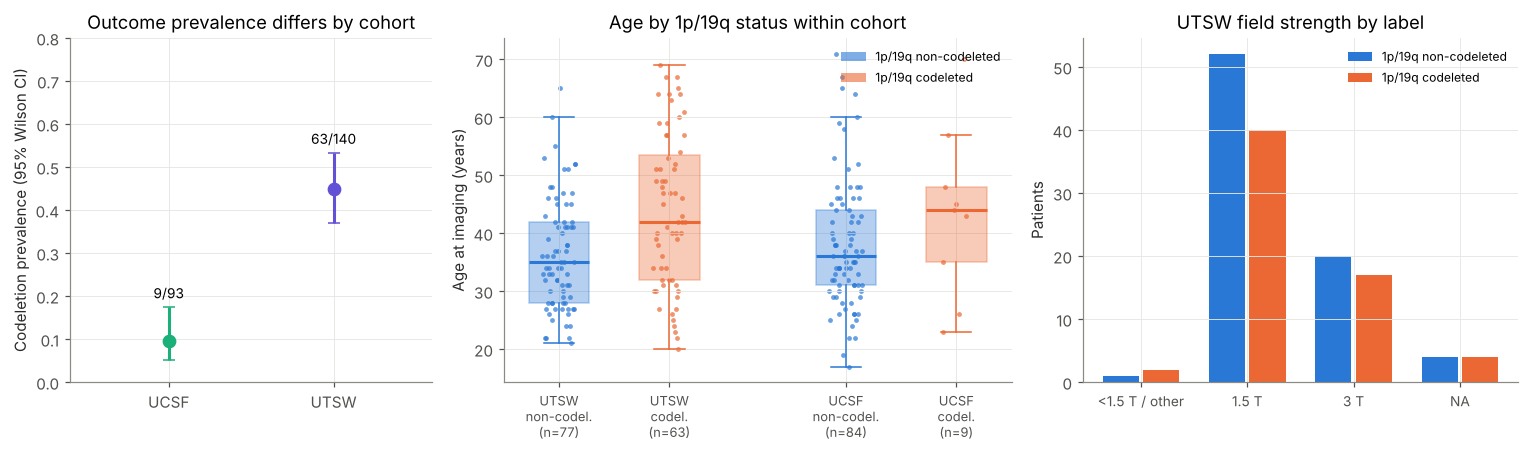

In [12]:
# Figures: prevalence by cohort, age by label within cohort, UTSW field strength by label
banner()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.4, 1.2]})

ax = axes[0]
for i, (coh, row) in enumerate(prevalence.iterrows()):
    lo, hi = wilson_ci(row["codeleted"], row["n"])
    ax.errorbar(i, row["prevalence"], yerr=[[row["prevalence"] - lo], [hi - row["prevalence"]]], fmt="o", ms=8,
                color=COHORT_COL[coh], capsize=4)
    ax.annotate(f"{int(row['codeleted'])}/{int(row['n'])}", (i, hi), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9)
ax.set_xticks(range(len(prevalence))); ax.set_xticklabels(prevalence.index); ax.set_xlim(-0.6, len(prevalence) - 0.4)
ax.set_ylim(0, 0.8); ax.set_ylabel("Codeletion prevalence (95% Wilson CI)")
ax.set_title("Outcome prevalence differs by cohort")

ax = axes[1]
pos = 0
ticks, labels = [], []
for coh in ["UTSW", "UCSF"]:
    for lab in [0, 1]:
        vals = eligible.loc[eligible["cohort"].eq(coh) & eligible["label"].eq(lab), "age"].values
        ax.boxplot(vals, positions=[pos], widths=0.55, patch_artist=True, showfliers=False,
                   boxprops=dict(facecolor=CLASS_COL[lab], alpha=0.35, edgecolor=CLASS_COL[lab]),
                   medianprops=dict(color=CLASS_COL[lab], linewidth=2), whiskerprops=dict(color=CLASS_COL[lab]),
                   capprops=dict(color=CLASS_COL[lab]))
        jitter = np.random.default_rng(3).uniform(-0.15, 0.15, len(vals))
        ax.scatter(pos + jitter, vals, s=10, color=CLASS_COL[lab], alpha=0.7, linewidths=0)
        ticks.append(pos); labels.append(f"{coh}\n{'codel.' if lab else 'non-codel.'}\n(n={len(vals)})")
        pos += 1
    pos += 0.6
ax.set_xticks(ticks); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel("Age at imaging (years)"); ax.set_title("Age by 1p/19q status within cohort")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=CLASS_COL[k], alpha=0.6, label=CLASS_NAME[k]) for k in [0, 1]], loc="upper right", fontsize=8)

ax = axes[2]
g = eligible[eligible["cohort"].eq("UTSW")].copy()
g["fs"] = g["field_strength_T"].map(lambda v: "NA" if pd.isna(v) else ("1.5 T" if v == 1.5 else ("3 T" if v == 3 else "<1.5 T / other")))
order = ["<1.5 T / other", "1.5 T", "3 T", "NA"]
cts = pd.crosstab(g["fs"], g["label"]).reindex(order, fill_value=0)
x = np.arange(len(order)); w = 0.38
for j, lab in enumerate([0, 1]):
    ax.bar(x + (j - 0.5) * w, cts[lab].values, width=w - 0.04, color=CLASS_COL[lab], label=CLASS_NAME[lab])
ax.set_xticks(x); ax.set_xticklabels(order, fontsize=9); ax.set_ylabel("Patients")
ax.set_title("UTSW field strength by label"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "06_cohort_audit"); plt.show()

**Reading the audit (the printed numbers above are authoritative; this paragraph explains how to interpret them).** If the cohort-only AUROC is well above 0.5, any pooled model can score above chance by recognising the cohort, for example through scanner-specific texture. That is why the primary analysis is restricted to one cohort, why every pooled comparison includes M0, and why pooled folds are stratified by cohort × label. Age is pre-operative and recorded in both cohorts; whatever its association with the label (table above), it enters M1 and M5 so that the habitat models are compared against it. Field strength is recorded only for UTSW, so it cannot be a pooled covariate; it is reported as a within-UTSW confounding check.

## 7. MRI, segmentation and radiomics quality control

For every eligible patient this section locates the four structural contrasts and the tumour segmentation, then checks that the files are readable, share one geometry, and that the segmentation contains tumour voxels. It records the label values found in each cohort's segmentations, so that the tumour-mask definition is verified rather than assumed.

If the imaging folders are absent, the section says so, lists the paths it looked for, and every downstream imaging cell reports `NOT EVALUATED`.

In `synthetic_smoke_test` mode a small synthetic dataset with fake IDs is generated first (cell 7.0) and used **instead of** the eligible cohort for sections 7–16. It exists only to prove the code runs end to end.

In [13]:
# 7.0 Synthetic smoke-test data (software verification only; runs only when GLIOMA_IMAGING_MODE=synthetic_smoke_test)
def make_synthetic_cohort(root, n_utsw=30, n_ucsf=18, shape=(60, 60, 60), seed=7):
    # Small skull-stripped-looking volumes with an ellipsoid tumour made of two compartments of equal volume
    # (inner sphere at r <= 0.794 holds half the volume). Non-codeleted: profile X inside, Y outside; codeleted:
    # swapped. Voxel composition is the same in both classes; only the radial arrangement differs. This exercises
    # the habitat, depth and spatial-metric code on data with real within-tumour structure.
    rng = np.random.default_rng(seed)
    rows = []
    zz, yy, xx = np.indices(shape)
    c = np.array(shape) / 2
    brain = ((zz - c[0]) / 27) ** 2 + ((yy - c[1]) / 26) ** 2 + ((xx - c[2]) / 25) ** 2 <= 1
    prof_x = {"T1": -0.5, "T1CE": -0.2, "T2": 1.6, "FLAIR": -0.4}
    prof_y = {"T1": -0.3, "T1CE": 0.3, "T2": 0.8, "FLAIR": 1.2}
    for coh, n, prev in [("UTSW", n_utsw, 0.45), ("UCSF", n_ucsf, 0.2)]:
        n_pos = max(3, int(round(n * prev)))
        labels = np.array([1] * n_pos + [0] * (n - n_pos)); rng.shuffle(labels)
        for i in range(n):
            pid = f"SYN-{coh}-{i + 1:03d}"
            lab = int(labels[i])
            small = (i == 0)                     # one tiny tumour per cohort: exercises the no-patch path
            radii = rng.uniform(3, 4, 3) if small else rng.uniform(12, 16, 3)
            centre = c + rng.uniform(-4, 4, 3)
            r = np.sqrt(((zz - centre[0]) / radii[0]) ** 2 + ((yy - centre[1]) / radii[1]) ** 2 + ((xx - centre[2]) / radii[2]) ** 2)
            tumour = (r <= 1) & brain
            inner = (r <= 0.794) & tumour
            outer = tumour & ~inner
            p_in, p_out = (prof_y, prof_x) if lab else (prof_x, prof_y)
            vols = {}
            for mod in CONFIG["modalities"]:
                v = np.where(brain, 1.0 + 0.08 * rng.standard_normal(shape), 0.0)
                v = np.where(inner, v + p_in[mod], v)
                v = np.where(outer, v + p_out[mod], v)
                vols[mod] = np.where(brain, np.clip(v, 0.05, None), 0.0).astype(np.float32)
            seg = np.zeros(shape, np.uint8); seg[outer] = 2; seg[inner] = 1
            files = CONFIG["imaging"][coh]["files"]
            d = Path(root) / CONFIG["imaging"][coh]["root"] / pid
            d.mkdir(parents=True, exist_ok=True)
            for mod, arr in vols.items():
                if coh == "UCSF" and i == 1 and mod == "FLAIR":
                    continue                     # one missing modality: exercises the missing-file path
                im = sitk.GetImageFromArray(arr); im.SetSpacing((1.0, 1.0, 1.0)); sitk.WriteImage(im, str(d / files[mod]))
            im = sitk.GetImageFromArray(seg); im.SetSpacing((1.0, 1.0, 1.0)); sitk.WriteImage(im, str(d / files["SEG"]))
            rows.append({"cohort": coh, "source_id": pid, "patient_id": pid, "label": lab,
                         "age": float(rng.integers(25, 70)), "sex": rng.choice(["M", "F"]), "grade": np.nan,
                         "field_strength_T": np.nan, "seg_provenance": "synthetic", "diagnosis": "synthetic",
                         "codel_status": "codeleted" if lab else "non-codeleted", "idh_status": "mutant",
                         "biopsy_prior_to_imaging": False})
    return pd.DataFrame(rows)

if SMOKE:
    assert HAVE_SITK, "SimpleITK is required for the smoke test"
    SMOKE_ROOT = OUT / "smoke_test_data"
    if SMOKE_ROOT.exists():
        shutil.rmtree(SMOKE_ROOT)
    study = make_synthetic_cohort(SMOKE_ROOT)
    IMAGING_DATA_ROOT = SMOKE_ROOT
    banner(); print(f"Synthetic cohort written to {SMOKE_ROOT}: {len(study)} fake patients")
else:
    # Primary-label patients plus the UCSF IDH-mutant patients whose label is resolvable only by the WHO 2021
    # integrated diagnosis (relative co-deletion / unknown). The latter are imaged and extracted so the label
    # sensitivity analysis can use them, but in_primary=False keeps them out of every primary analysis.
    extras = sens[sens["cohort"].eq("UCSF") & sens["codel_status"].isin(["relative_codeletion", "unknown"])
                  & sens["label_who2021_resolved"].notna()].copy()
    extras["label"] = extras["label_who2021_resolved"].astype(int)
    study = pd.concat([eligible.assign(in_primary=True), extras.assign(in_primary=False)], ignore_index=True)
    IMAGING_DATA_ROOT = CONFIG["data_root"]
if "in_primary" not in study:
    study["in_primary"] = True
assert study["patient_id"].is_unique
print("Patients entering imaging QC:", len(study), "| by cohort, label and primary-set membership:")
display(study.groupby(["cohort", "in_primary", "label"]).size().unstack(fill_value=0))

Patients entering imaging QC: 243 | by cohort, label and primary-set membership:


label               0   1
cohort in_primary        
UCSF   False        6   4
       True        84   9
UTSW   True        77  63

In [14]:
def candidate_dirs(row):
    coh = row["cohort"]
    root = IMAGING_DATA_ROOT / CONFIG["imaging"][coh]["root"]
    names = [row["source_id"], row["patient_id"]]
    m = re.match(r"^UCSF-PDGM-(\d+)$", str(row["patient_id"]))
    if coh == "UCSF" and m:
        n = int(m.group(1))
        names = [f"UCSF-PDGM-{n:03d}", f"UCSF-PDGM-{n:04d}", f"UCSF-PDGM-{n:04d}_nifti"] + names
    return [root / nm for nm in dict.fromkeys(names)]

def locate_case(row):
    files = CONFIG["imaging"][row["cohort"]]["files"]
    for d in candidate_dirs(row):
        if d.is_dir():
            paths = {k: d / v for k, v in files.items()}
            missing = [k for k, p in paths.items() if not p.is_file()]
            return {"subject_dir": str(d), "paths": {k: str(p) for k, p in paths.items()}, "missing": missing}
    return {"subject_dir": None, "paths": {}, "missing": ["subject folder"]}

def same_geometry(a, b, tol=1e-3):
    return (a.GetSize() == b.GetSize() and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=tol)
            and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=tol) and np.allclose(a.GetDirection(), b.GetDirection(), atol=tol))

def qc_case(row):
    out = {"patient_id": row["patient_id"], "cohort": row["cohort"], "label": row["label"]}
    loc = locate_case(row)
    out.update(subject_dir=loc["subject_dir"], missing=", ".join(loc["missing"]))
    if loc["missing"]:
        out["qc_status"] = "missing_files"; return out
    try:
        seg = sitk.ReadImage(loc["paths"]["SEG"])
        arr = sitk.GetArrayViewFromImage(seg)
        labs = np.unique(arr)
        out["seg_labels"] = " ".join(str(int(v)) for v in labs)
        out["spacing"] = " x ".join(f"{s:.2f}" for s in seg.GetSpacing())
        out["size"] = " x ".join(str(s) for s in seg.GetSize())
        tum = np.isin(arr, CONFIG["tumour_labels"]) if CONFIG["tumour_labels"] else arr > 0
        out["tumour_volume_ml"] = float(tum.sum() * np.prod(seg.GetSpacing()) / 1000.0)
        mism = []
        for mod in CONFIG["modalities"]:
            r = sitk.ImageFileReader(); r.SetFileName(loc["paths"][mod]); r.ReadImageInformation()
            if not (r.GetSize() == seg.GetSize() and np.allclose(r.GetSpacing(), seg.GetSpacing(), atol=1e-3)
                    and np.allclose(r.GetOrigin(), seg.GetOrigin(), atol=1e-3)):
                mism.append(mod)
        out["geometry_mismatch"] = ", ".join(mism)
        out["qc_status"] = "no_tumour_voxels" if out["tumour_volume_ml"] == 0 else "ok"
    except Exception as exc:
        out["qc_status"] = f"unreadable: {type(exc).__name__}: {exc}"
    out["paths"] = json.dumps(loc["paths"])
    return out

imaging_root_exists = any((IMAGING_DATA_ROOT / CONFIG["imaging"][c]["root"]).is_dir() for c in ["UTSW", "UCSF"])
if not HAVE_SITK:
    print("NOT EVALUATED: SimpleITK is not installed (see requirements.txt).")
    qc = pd.DataFrame()
elif not imaging_root_exists:
    print("NOT EVALUATED: no imaging folder found. Looked for:")
    for c in ["UTSW", "UCSF"]:
        print("  ", IMAGING_DATA_ROOT / CONFIG["imaging"][c]["root"])
    print("Example expected case folders:")
    for _, r in study.groupby("cohort").head(2).iterrows():
        print("  ", " | ".join(str(p) for p in candidate_dirs(r)[:3]))
    qc = pd.DataFrame()
else:
    banner()
    rows = [qc_case(r) for _, r in study.iterrows()]
    qc = pd.DataFrame(rows)
    display(qc["qc_status"].value_counts().rename("patients").to_frame())
    print("Segmentation label sets by cohort:")
    display(qc[qc["qc_status"].eq("ok")].groupby("cohort")["seg_labels"].value_counts().rename("patients").to_frame())
    display(qc.groupby(["cohort", "label"])["qc_status"].apply(lambda s: (s == "ok").sum()).unstack())
    if (qc["geometry_mismatch"].fillna("") != "").any():
        print("Cases whose modalities do not share the segmentation grid (they are resampled onto it in section 8):")
        display(qc.loc[qc["geometry_mismatch"].fillna("") != "", ["patient_id", "cohort", "geometry_mismatch"]])
    save_table(qc.drop(columns=["paths"], errors="ignore"), "07_imaging_qc")
IMAGING_AVAILABLE = (not qc.empty) and qc["qc_status"].eq("ok").any()
record_check("Imaging available for at least one eligible patient", IMAGING_AVAILABLE,
             "imaging sections will run" if IMAGING_AVAILABLE else "imaging sections will report NOT EVALUATED",
             status=None if IMAGING_AVAILABLE else "NOT AVAILABLE")

NOT EVALUATED: no imaging folder found. Looked for:
   /home/claude/work/data/UTSW_processed
   /home/claude/work/data/UCSF/images
Example expected case folders:
   /home/claude/work/data/UTSW_processed/BT0003 | /home/claude/work/data/UTSW_processed/UTSW-BT0003
   /home/claude/work/data/UTSW_processed/BT0007 | /home/claude/work/data/UTSW_processed/UTSW-BT0007
   /home/claude/work/data/UCSF/images/UCSF-PDGM-031 | /home/claude/work/data/UCSF/images/UCSF-PDGM-0031 | /home/claude/work/data/UCSF/images/UCSF-PDGM-0031_nifti
   /home/claude/work/data/UCSF/images/UCSF-PDGM-061 | /home/claude/work/data/UCSF/images/UCSF-PDGM-0061 | /home/claude/work/data/UCSF/images/UCSF-PDGM-0061_nifti
NOT AVAILABLE Imaging available for at least one eligible patient — imaging sections will report NOT EVALUATED


## 8. Patch construction and feature extraction

Changes from iteration 2, each fixing a verified problem:

| Change | Why |
| --- | --- |
| Shape features are computed **once per patch** and stored as `shape__*`; intensity and texture are stored as `<MOD>__<feature>`. | Iteration 2 copied the 14 shape features into every modality row, creating 56 identical columns in the habitat clustering. |
| Shape features are **excluded from habitat clustering** (section 9) and kept only as descriptors. | Patch shape describes how much tumour mask a patch holds, i.e. its position at the margin, not tissue signal. Leaving it in would make the core/edge metrics partly circular. |
| A Euclidean distance transform of the whole tumour mask gives each patch an anatomical **depth** (mean distance in mm of its tumour voxels to the tumour boundary). | Core/edge is now defined by distance to the actual tumour surface, not by distance to the centroid of patch corners. |
| Whole-tumour radiomics (`wt_*`) and tumour volume are extracted for every patient with a readable mask, **including** patients with no valid patch. | M1 and M2 need them, and excluded patients can be compared with included ones. |
| Optional N4 bias-field correction before z-scoring. | UTSW spans five vendors and 0.3–3 T; neither data descriptor states that bias correction was applied. |
| Per-patient caching keyed by a configuration fingerprint. | Kept from iteration 2: a changed setting invalidates the cache instead of silently reusing it. |

Patches keep the iteration-2 geometry by default (32³ voxels, stride 16, at least 25% tumour), so results stay comparable; `CONFIG["patch_size"]` can be reduced to keep more small tumours (exclusions are reported by class below).

In [15]:
FINGERPRINT_KEYS = ["modalities", "tumour_labels", "n4_bias_correction", "target_spacing", "patch_size", "patch_stride",
                    "min_tumour_fraction", "bin_width", "texture_classes", "imaging_mode"]

def config_fingerprint():
    blob = json.dumps({k: CONFIG[k] for k in FINGERPRINT_KEYS}, sort_keys=True, default=str)
    return hashlib.sha1(blob.encode()).hexdigest()[:12]

def n4_correct(img, mask):
    shrink = 4
    small = sitk.Shrink(img, [shrink] * img.GetDimension())
    small_mask = sitk.Shrink(mask, [shrink] * img.GetDimension())
    corr = sitk.N4BiasFieldCorrectionImageFilter()
    corr.SetMaximumNumberOfIterations([50, 50, 30])
    corr.Execute(small, small_mask)
    log_bias = corr.GetLogBiasFieldAsImage(img)
    return sitk.Cast(img / sitk.Exp(log_bias), sitk.sitkFloat32)

def resample(img, reference=None, spacing=None, interpolator=None):
    f = sitk.ResampleImageFilter()
    f.SetInterpolator(interpolator if interpolator is not None else sitk.sitkLinear)
    f.SetDefaultPixelValue(0)
    if reference is not None:
        f.SetReferenceImage(reference)
    else:
        in_sp, in_sz = np.array(img.GetSpacing()), np.array(img.GetSize())
        out_sp = np.array(spacing, float)
        f.SetOutputSpacing(out_sp.tolist())
        f.SetSize([int(s) for s in np.maximum(np.round(in_sz * in_sp / out_sp), 1)])
        f.SetOutputOrigin(img.GetOrigin()); f.SetOutputDirection(img.GetDirection())
    return f.Execute(img)

def load_case(paths):
    # Returns arrays in (z, y, x) order, spacing in the same order, and log notes.
    notes = []
    seg = sitk.ReadImage(paths["SEG"])
    if not np.allclose(seg.GetSpacing(), CONFIG["target_spacing"], atol=1e-3):
        seg = resample(seg, spacing=CONFIG["target_spacing"], interpolator=sitk.sitkNearestNeighbor)
        notes.append("segmentation resampled to target spacing")
    seg_arr = sitk.GetArrayFromImage(seg)
    mask = np.isin(seg_arr, CONFIG["tumour_labels"]) if CONFIG["tumour_labels"] else seg_arr > 0
    imgs = {}
    for mod in CONFIG["modalities"]:
        img = sitk.ReadImage(paths[mod], sitk.sitkFloat32)
        if not same_geometry(img, seg):
            img = resample(img, reference=seg); notes.append(f"{mod} resampled onto segmentation grid")
        arr = sitk.GetArrayFromImage(img).astype(np.float32)
        brain = arr != 0
        if brain.sum() < 1000:
            raise ValueError(f"{mod}: fewer than 1000 non-zero voxels; is the image skull-stripped and non-empty?")
        if CONFIG["n4_bias_correction"]:
            bm = sitk.GetImageFromArray(brain.astype(np.uint8)); bm.CopyInformation(img)
            arr = sitk.GetArrayFromImage(n4_correct(img, bm)).astype(np.float32)
            arr[~brain] = 0
        mu, sd = float(arr[brain].mean()), float(arr[brain].std())
        if sd < 1e-8:
            raise ValueError(f"{mod}: no intensity variation inside the brain")
        arr = np.where(brain, (arr - mu) / sd, 0).astype(np.float32)
        imgs[mod] = arr
    spacing_zyx = tuple(reversed(seg.GetSpacing()))
    return mask, imgs, spacing_zyx, notes

def axis_starts(lo, hi, size, dim):
    stride = CONFIG["patch_stride"]
    if dim < size:
        raise ValueError(f"volume axis ({dim}) smaller than patch size ({size})")
    if hi - lo <= size:
        starts = [int(round((lo + hi) / 2 - size / 2))]
    else:
        starts = list(range(lo, hi - size + 1, stride))
        if starts[-1] + size < hi:
            starts.append(hi - size)
    return sorted({min(max(s, 0), dim - size) for s in starts})

def generate_patches(mask, depth):
    P = CONFIG["patch_size"]
    idx = np.argwhere(mask)
    lo, hi = idx.min(0), idx.max(0) + 1
    axes = [axis_starts(int(lo[a]), int(hi[a]), P, mask.shape[a]) for a in range(3)]
    n_vox = P ** 3
    kept, n_cand = [], 0
    for s in itertools.product(*axes):
        n_cand += 1
        sl = tuple(slice(a, a + P) for a in s)
        win = mask[sl]
        n_t = int(win.sum())
        if n_t / n_vox >= CONFIG["min_tumour_fraction"] - 1e-12:
            kept.append({"z0": s[0], "y0": s[1], "x0": s[2], "n_tumour_vox": n_t, "tumour_fraction": n_t / n_vox,
                         "depth_mean_mm": float(depth[sl][win].mean())})
    return kept, n_cand

def make_extractors():
    settings = dict(binWidth=CONFIG["bin_width"], normalize=False, resampledPixelSpacing=None, force2D=False,
                    distances=[1], symmetricalGLCM=True, voxelArrayShift=0, label=1, additionalInfo=False,
                    geometryTolerance=1e-3)
    def make(classes):
        ext = featureextractor.RadiomicsFeatureExtractor(**settings)
        ext.disableAllFeatures()
        for c in classes:
            ext.enableFeatureClassByName(c)
        ext.disableAllImageTypes(); ext.enableImageTypeByName("Original")
        return ext
    return make(CONFIG["texture_classes"]), make(["shape"])

def to_sitk(arr, spacing_zyx):
    im = sitk.GetImageFromArray(arr); im.SetSpacing(tuple(float(s) for s in reversed(spacing_zyx)))
    return im

def run_ext(ext, img_arr, mask_arr, spacing, prefix):
    res = ext.execute(to_sitk(img_arr, spacing), to_sitk(mask_arr.astype(np.uint8), spacing), label=1)
    # Some PyRadiomics features (e.g. GLCM MCC) can come back as complex numbers with ~0 imaginary part
    return {f"{prefix}{k}": float(np.real(v)) for k, v in res.items() if not k.startswith("diagnostics_")}

def extract_patient(row_dict, paths):
    # One patient: patch features + whole-tumour features + volume. Writes a cache file and returns a status dict.
    logging.getLogger("radiomics").setLevel(logging.ERROR)
    pid, coh = row_dict["patient_id"], row_dict["cohort"]
    fp = config_fingerprint()
    cdir = OUT / "features" / "per_patient"; cdir.mkdir(parents=True, exist_ok=True)
    csv_path, st_path = cdir / f"{pid}.csv", cdir / f"{pid}.json"
    if st_path.is_file():
        st = json.loads(st_path.read_text())
        if st.get("fingerprint") == fp and (st["status"] != "ok" or csv_path.is_file()):
            return st
    t0 = time.time()
    st = {"patient_id": pid, "cohort": coh, "status": "ok", "message": "", "fingerprint": fp, "n_candidates": 0,
          "n_patches": 0, "n_failed_patches": 0, "tumour_volume_ml": np.nan, "max_depth_mm": np.nan, "wt": {}}
    try:
        mask, imgs, sp, notes = load_case(paths)
        st["message"] = "; ".join(notes)
        st["tumour_volume_ml"] = float(mask.sum() * np.prod(sp) / 1000.0)
        if mask.sum() == 0:
            raise ValueError("no tumour voxels")
        depth = distance_transform_edt(mask, sampling=sp).astype(np.float32)
        st["max_depth_mm"] = float(depth.max())
        tex_ext, shape_ext = make_extractors()
        # whole-tumour features (cropped to the bounding box + 2 voxels)
        idx = np.argwhere(mask); lo = np.maximum(idx.min(0) - 2, 0); hi = np.minimum(idx.max(0) + 3, mask.shape)
        bb = tuple(slice(a, b) for a, b in zip(lo, hi))
        wt = run_ext(shape_ext, imgs[CONFIG["modalities"][0]][bb], mask[bb], sp, "wt_shape__")
        for mod in CONFIG["modalities"]:
            wt.update(run_ext(tex_ext, imgs[mod][bb], mask[bb], sp, f"wt_{mod}__"))
        st["wt"] = wt
        patches, n_cand = generate_patches(mask, depth)
        st["n_candidates"] = n_cand
        rows = []
        P = CONFIG["patch_size"]
        for k, p in enumerate(patches):
            sl = tuple(slice(p[a], p[a] + P) for a in ["z0", "y0", "x0"])
            try:
                feats = run_ext(shape_ext, imgs[CONFIG["modalities"][0]][sl], mask[sl], sp, "shape__")
                for mod in CONFIG["modalities"]:
                    feats.update(run_ext(tex_ext, imgs[mod][sl], mask[sl], sp, f"{mod}__"))
            except Exception as exc:
                st["n_failed_patches"] += 1
                continue
            rows.append({"patient_id": pid, "cohort": coh, "patch_idx": k, **p,
                         "depth_norm": p["depth_mean_mm"] / st["max_depth_mm"], **feats})
        st["n_patches"] = len(rows)
        if rows:
            pd.DataFrame(rows).to_csv(csv_path, index=False)
        else:
            st["status"] = "no_patches"
            st["message"] += f"; 0/{n_cand} candidate patches reached tumour fraction {CONFIG['min_tumour_fraction']}"
    except Exception as exc:
        st["status"] = "error"; st["message"] = f"{type(exc).__name__}: {exc}"
    st["seconds"] = round(time.time() - t0, 1)
    st_path.write_text(json.dumps(st, default=float))
    return st

In [16]:
if not IMAGING_AVAILABLE:
    print("NOT EVALUATED: no readable imaging (section 7). Patch extraction skipped.")
    patient_img = pd.DataFrame(); patches = pd.DataFrame()
elif not HAVE_RADIOMICS:
    raise ImportError("PyRadiomics is required for feature extraction; install the pinned version from requirements.txt")
else:
    banner()
    todo = qc[qc["qc_status"].eq("ok")]
    jobs = [(study.set_index("patient_id").loc[r["patient_id"]].to_dict() | {"patient_id": r["patient_id"]},
             json.loads(r["paths"])) for _, r in todo.iterrows()]
    t0 = time.time()
    if HAVE_JOBLIB and CONFIG["n_jobs"] > 1:
        statuses = Parallel(n_jobs=CONFIG["n_jobs"], verbose=0)(delayed(extract_patient)(rd, p) for rd, p in jobs)
    else:
        statuses = [extract_patient(rd, p) for rd, p in jobs]
    print(f"Extraction finished for {len(statuses)} patients in {time.time() - t0:.0f} s (cached patients are instant).")
    patient_img = pd.DataFrame([{k: v for k, v in s.items() if k != "wt"} for s in statuses])
    wt = pd.DataFrame([s["wt"] for s in statuses], index=[s["patient_id"] for s in statuses])
    patient_img = patient_img.set_index("patient_id").join(wt)
    frames = [pd.read_csv(OUT / "features" / "per_patient" / f"{s['patient_id']}.csv") for s in statuses if s["status"] == "ok"]
    patches = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    display(patient_img["status"].value_counts().rename("patients").to_frame())
    if (patient_img["status"] == "error").any():
        display(patient_img.loc[patient_img["status"].eq("error"), ["cohort", "message"]])
    print(f"Patches: {len(patches)} from {patches['patient_id'].nunique() if len(patches) else 0} patients")

NOT EVALUATED: no readable imaging (section 7). Patch extraction skipped.


In [17]:
# Feature naming checks and exclusion accounting by class
if IMAGING_AVAILABLE and len(patches):
    banner()
    MODS = CONFIG["modalities"]
    shape_cols = [c for c in patches.columns if c.startswith("shape__")]
    mod_cols = {m: [c for c in patches.columns if c.startswith(f"{m}__")] for m in MODS}
    n_per_mod = {m: len(v) for m, v in mod_cols.items()}
    record_check("Shape features stored once per patch (not per modality)",
                 not any(c.startswith(f"{m}__") and "_shape_" in c for m in MODS for c in patches.columns),
                 f"{len(shape_cols)} shape columns")
    record_check("Same number of features for every modality", len(set(n_per_mod.values())) == 1, json.dumps(n_per_mod))
    record_check("No duplicated patch rows", not patches.duplicated(["patient_id", "patch_idx"]).any())
    PATCH_META = ["patient_id", "cohort", "patch_idx", "z0", "y0", "x0", "n_tumour_vox", "tumour_fraction", "depth_mean_mm", "depth_norm"]

    acc = study.set_index("patient_id")[["cohort", "label", "in_primary"]].join(
        qc.set_index("patient_id")[["qc_status"]]).join(patient_img[["status", "n_patches", "tumour_volume_ml"]])
    acc["outcome"] = np.select([acc["qc_status"].ne("ok"), acc["status"].ne("ok")],
                               ["excluded: imaging QC", "excluded: no valid patch / extraction error"], "habitat-evaluable")
    evaluable_ids = acc.index[acc["outcome"].eq("habitat-evaluable")].tolist()   # includes label-sensitivity extras
    acc = acc[acc["in_primary"]]                                                   # accounting on the primary label set
    exclusion = pd.crosstab([acc["cohort"], acc["outcome"]], acc["label"].map(CLASS_NAME))
    display(exclusion)
    save_table(exclusion, "08_exclusions_by_class")
    exc_any = acc["outcome"].ne("habitat-evaluable")
    tab = pd.crosstab(exc_any, acc["label"]).reindex(index=[True, False], columns=[1, 0], fill_value=0)
    if tab.values.min() >= 0 and tab.shape == (2, 2):
        p_exc = stats.fisher_exact(tab.values)[1]
        print(f"Excluded: {tab.loc[True, 1]}/{tab[1].sum()} codeleted vs {tab.loc[True, 0]}/{tab[0].sum()} non-codeleted (Fisher p = {p_exc:.3g})")
    vol = acc.dropna(subset=["tumour_volume_ml"])
    if len(vol):
        print("Tumour volume (mL) by evaluability and class (median [IQR]):")
        display(vol.groupby(["outcome", "label"])["tumour_volume_ml"].describe()[["count", "25%", "50%", "75%"]])
else:
    print("NOT EVALUATED: no patch features.")
    evaluable_ids = []

NOT EVALUATED: no patch features.


## 9. Habitat model development and stability

A **habitat model** is a learned transformation: feature filtering → standardisation → PCA (95% variance) → k-means. In iteration 2 it was fitted once on all patients before cross-validation, so held-out patients shaped the habitats used to score them. Here the whole model, including the choice of K, is a class with `fit` and `predict`, and section 12 refits it inside every training fold. Held-out patches are only ever *assigned* to habitats learned from training patients.

**Choosing K.** The elbow of the inertia curve is not a stability criterion. For each K in `CONFIG["habitat"]["k_grid"]` the model is refitted on bootstrap resamples of *patients* and the resulting assignments of all training patches are compared with the reference solution by the adjusted Rand index (ARI). K is the smallest value whose mean ARI is within `stability_tolerance` of the best, among solutions where every habitat holds at least `min_habitat_share` of patches. Silhouette and inertia are reported alongside for transparency.

**Descriptive model.** One extra model is fitted on all habitat-evaluable patients **for description only** (phenotype heatmap, cohort cross-tab, stability curve). It is never used to score a patient in any evaluation.

In [18]:
def habitat_columns(df):
    cols = [c for c in df.columns if any(c.startswith(f"{m}__") for m in CONFIG["modalities"])]
    assert not any(c.startswith("shape__") for c in cols)
    return cols

class HabitatModel:
    # Unsupervised: never sees labels. fit() on training-patient patches only; predict() for any patches.
    def __init__(self, k=None, seed=0, harmonisation=None):
        self.k_fixed, self.seed, self.harmonisation = k, seed, harmonisation
        self.hc = CONFIG["habitat"]
        self.transductive_cohorts_ = []

    def _harmonise(self, X, cohorts, fit):
        # Optional per-cohort z-scoring (sensitivity analysis). Parameters come from training patches; a cohort
        # never seen in training (leave-one-cohort-out) gets label-free parameters from its own patches and is flagged.
        if self.harmonisation != "per_cohort_zscore":
            return X
        X = X.copy()
        if fit:
            self.coh_stats_ = {}
        for c in np.unique(cohorts):
            sel = cohorts == c
            if c not in self.coh_stats_:
                self.coh_stats_[c] = (X[sel].mean(0), X[sel].std(0) + 1e-8)
                if not fit:
                    self.transductive_cohorts_.append(c)
            mu, sd = self.coh_stats_[c]
            X[sel] = (X[sel] - mu) / sd
        return X

    def fit(self, df):
        cols = habitat_columns(df)
        X = df[cols].to_numpy(float)
        keep = np.isfinite(X).all(0) & (np.nanstd(X, 0) > 1e-8)
        self.cols_ = [c for c, k in zip(cols, keep) if k]
        self.dropped_ = [c for c, k in zip(cols, keep) if not k]
        X = self._harmonise(df[self.cols_].to_numpy(float), df["cohort"].to_numpy(), fit=True)
        self.scaler_ = StandardScaler().fit(X)
        Z = self.scaler_.transform(X)
        self.pca_ = PCA(n_components=self.hc["pca_variance"] if min(Z.shape) > 2 else 1, random_state=self.seed).fit(Z)
        Zp = self.pca_.transform(Z)
        pids = df["patient_id"].to_numpy()
        if self.k_fixed is None and self.hc["fixed_k"] is None:
            self.k_, self.selection_ = self._select_k(Zp, pids)
        else:
            self.k_ = int(self.k_fixed or self.hc["fixed_k"]); self.selection_ = None
        self.km_ = KMeans(n_clusters=self.k_, n_init=self.hc["kmeans_n_init"], random_state=self.seed).fit(Zp)
        self.train_patients_ = sorted(set(pids))
        return self

    def _select_k(self, Zp, pids):
        rng = np.random.default_rng(self.seed)
        uniq = np.unique(pids)
        by_pid = {p: np.flatnonzero(pids == p) for p in uniq}
        rows = []
        for k in self.hc["k_grid"]:
            if k >= len(Zp):
                continue
            ref = KMeans(n_clusters=k, n_init=self.hc["selection_n_init"], random_state=self.seed).fit(Zp)
            ref_lab = ref.labels_
            share = np.bincount(ref_lab, minlength=k) / len(ref_lab)
            aris = []
            for b in range(self.hc["stability_bootstraps"]):
                boot = rng.choice(uniq, len(uniq), replace=True)
                idx = np.concatenate([by_pid[p] for p in boot])
                km = KMeans(n_clusters=k, n_init=self.hc["selection_n_init"], random_state=self.seed + b + 1).fit(Zp[idx])
                aris.append(adjusted_rand_score(ref_lab, km.predict(Zp)))
            ss = min(self.hc["silhouette_sample"], len(Zp))
            sil = silhouette_score(Zp, ref_lab, sample_size=ss, random_state=self.seed) if k > 1 else np.nan
            rows.append({"K": k, "ARI_mean": np.mean(aris), "ARI_sd": np.std(aris), "silhouette": sil,
                         "inertia": ref.inertia_, "min_share": share.min()})
        sel = pd.DataFrame(rows)
        ok = sel[sel["min_share"] >= self.hc["min_habitat_share"]]
        if ok.empty:
            ok = sel
        best = ok["ARI_mean"].max()
        k = int(ok.loc[ok["ARI_mean"] >= best - self.hc["stability_tolerance"], "K"].min())
        return k, sel

    def predict(self, df):
        X = self._harmonise(df[self.cols_].to_numpy(float), df["cohort"].to_numpy(), fit=False)
        X = np.where(np.isfinite(X), X, 0.0)
        return self.km_.predict(self.pca_.transform(self.scaler_.transform(X)))

In [19]:
# Descriptive habitat model on all habitat-evaluable patients (description only — never used for evaluation)
DESC = None
if len(evaluable_ids) >= 10:
    banner()
    pe = patches[patches["patient_id"].isin(evaluable_ids)].reset_index(drop=True).copy()
    t0 = time.time()
    DESC = HabitatModel(seed=CONFIG["seed"]).fit(pe)
    pe = pe.assign(habitat=DESC.predict(pe))
    print(f"Descriptive model: {len(pe)} patches, {len(DESC.cols_)} habitat features "
          f"({len(DESC.dropped_)} dropped as constant/non-finite), {DESC.pca_.n_components_} PCs, K = {DESC.k_} "
          f"({time.time() - t0:.0f} s)")
    if DESC.selection_ is not None:
        display(DESC.selection_.round(3))
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
        s = DESC.selection_
        ax[0].errorbar(s["K"], s["ARI_mean"], yerr=s["ARI_sd"], fmt="o-", color=CONFIG["colors"]["models"][0], capsize=3)
        ax[0].axvline(DESC.k_, color="#8a8984", ls="--", lw=1); ax[0].set_xlabel("K"); ax[0].set_ylabel("Bootstrap ARI (mean ± SD)")
        ax[0].set_title(f"Stability; selected K = {DESC.k_}")
        ax[1].plot(s["K"], s["silhouette"], "o-", color=CONFIG["colors"]["models"][2])
        ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette"); ax[1].set_title("Silhouette (reported, not used to select)")
        fig.tight_layout(); save_fig(fig, "09_k_selection_descriptive"); plt.show()

    # Phenotypes from the EXACT mean-intensity columns (iteration 2 also matched MeanAbsoluteDeviation)
    mean_cols = [f"{m}__original_firstorder_Mean" for m in CONFIG["modalities"]]
    assert all(c in pe.columns for c in mean_cols) and len(set(mean_cols)) == len(CONFIG["modalities"])
    record_check("Phenotype columns are exact Mean features (no MeanAbsoluteDeviation)",
                 not any("MeanAbsoluteDeviation" in c for c in mean_cols), ", ".join(mean_cols))
    pheno = pe.groupby("habitat")[mean_cols].median()
    pheno.columns = CONFIG["modalities"]
    pheno.insert(0, "patches", pe.groupby("habitat").size())
    pheno["median depth_norm (0 = margin)"] = pe.groupby("habitat")["depth_norm"].median()
    display(pheno.round(2))
    save_table(pheno, "09_habitat_phenotypes_descriptive")
    fig, ax = plt.subplots(figsize=(5.5, 0.5 * DESC.k_ + 1.5))
    vals = pheno[CONFIG["modalities"]].to_numpy()
    lim = np.nanmax(np.abs(vals))
    im = ax.imshow(vals, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(CONFIG["modalities"]))); ax.set_xticklabels(CONFIG["modalities"])
    ax.set_yticks(range(DESC.k_)); ax.set_yticklabels([f"H{k} (n={n})" for k, n in pheno["patches"].items()])
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(vals[i, j]) > 0.6 * lim else "#0b0b0b")
    ax.grid(False); fig.colorbar(im, ax=ax, label="median patch mean intensity (brain z-score)")
    ax.set_title("Habitat phenotypes (descriptive model)")
    fig.tight_layout(); save_fig(fig, "09_habitat_phenotypes"); plt.show()

    # Do habitats separate cohorts? (a habitat that is one cohort's scanner signature cannot be biology)
    hx = pd.crosstab(pe["habitat"], pe["cohort"])
    v = cramers_v(hx.values) if hx.shape[1] > 1 else np.nan
    print(f"Habitat x cohort (patches); Cramér's V = {v:.2f}")
    display(hx.assign(**{"UCSF share": (hx.get("UCSF", 0) / hx.sum(axis=1)).round(2)}))
    dom = pe.groupby("patient_id")["habitat"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
    print(f"Per-patient share of the dominant habitat: median {dom.median():.2f}; "
          f"{(dom >= 0.9).mean():.0%} of patients have ≥90% of patches in one habitat.")
    DESC_SUMMARY = {"K": DESC.k_, "n_patches": len(pe), "cramers_v_habitat_cohort": v, "dominant_share_median": dom.median()}
else:
    print("NOT EVALUATED: fewer than 10 habitat-evaluable patients.")
    DESC_SUMMARY = None

NOT EVALUATED: fewer than 10 habitat-evaluable patients.


## 10. Patient-level habitat features

Given habitat assignments, each patient is summarised by two pre-specified feature groups.

**Composition (M3)** — depends only on how many patches fall in each habitat:

- `comp_h{k}`: fraction of the patient's patches in habitat *k*.
- `entropy_norm`: Shannon entropy of those fractions divided by log K. It is a function of composition alone, so it is a composition feature, not a spatial one.
- `n_habitats_present`.

**Spatial arrangement (added in M4)** — each metric is constructed so that its expected value under random arrangement does not depend on composition:

- `mixing_excess`: observed fraction of face-adjacent patch pairs (neighbours one stride apart on the patch grid) with different habitats, minus its mean under a **within-patient permutation null** that shuffles habitat labels across that patient's patch positions (composition fixed). Positive = more intermixed than chance.
- `radial_eta2_excess`: share of the variance in anatomical depth explained by habitat (η²), minus its mean under the same null. Positive = habitats sit at more distinct depths than chance.
- The matching z-scores (`mixing_z`, `radial_eta2_z`) are computed for description only. They are not model features because a z-score grows with the number of patches for the same underlying effect, which would re-introduce tumour size.
- `depth_shift_h{k}`: mean normalised depth of habitat-*k* patches minus the patient's mean patch depth (0 = margin, 1 = deepest). Its expectation under random arrangement is 0 whatever the composition. An absent habitat gets 0 (no shift), not a ratio.
- `spatial_defined`: 1 if the patient has at least `CONFIG["spatial"]["min_patches"]` patches and at least one adjacent pair; otherwise the spatial metrics are set to their null value (0) and this indicator is 0, so small tumours stay in the analysis instead of being dropped.

The iteration-2 localisation ratio `(edge + 1e-5)/(core + 1e-5)` is removed: it returned about 10⁴ when a habitat was absent from the core and 1.0 when a habitat was absent altogether.

In [20]:
def grid_pairs(starts, stride):
    lookup = {tuple(s): i for i, s in enumerate(starts)}
    ii, jj = [], []
    for i, s in enumerate(starts):
        for ax in range(3):
            nb = list(s); nb[ax] += stride
            j = lookup.get(tuple(nb))
            if j is not None:
                ii.append(i); jj.append(j)
    return np.array(ii, int), np.array(jj, int)

def eta2_rows(labels_2d, depth, K):
    # labels_2d: (R, n) habitat labels per row; returns eta^2 per row
    R, n = labels_2d.shape
    tot = ((depth - depth.mean()) ** 2).sum()
    if tot <= 0:
        return np.full(R, np.nan)
    offs = labels_2d + K * np.arange(R)[:, None]
    sums = np.bincount(offs.ravel(), weights=np.tile(depth, R), minlength=R * K).reshape(R, K)
    cnts = np.bincount(offs.ravel(), minlength=R * K).reshape(R, K)
    means = np.divide(sums, cnts, out=np.zeros_like(sums), where=cnts > 0)
    between = (cnts * (means - depth.mean()) ** 2).sum(1)
    return between / tot

def patient_habitat_features(hab, starts, depth_norm, K, rng, n_null, shuffle=False):
    n = len(hab)
    if shuffle:
        hab = rng.permutation(hab)          # spatial-arrangement null: composition preserved, positions scrambled
    comp = np.bincount(hab, minlength=K) / n
    nz = comp[comp > 0]
    f = {f"comp_h{k}": comp[k] for k in range(K)}
    f["entropy_norm"] = float(-(nz * np.log(nz)).sum() / math.log(K)) if K > 1 else 0.0
    f["n_habitats_present"] = int((comp > 0).sum())
    for k in range(K):
        sel = hab == k
        f[f"depth_shift_h{k}"] = float(depth_norm[sel].mean() - depth_norm.mean()) if sel.any() else 0.0
    i, j = grid_pairs(starts, CONFIG["patch_stride"])
    defined = n >= CONFIG["spatial"]["min_patches"] and len(i) > 0
    f["spatial_defined"] = int(defined)
    f["mixing_obs"], f["mixing_excess"], f["mixing_z"] = np.nan, 0.0, 0.0
    f["radial_eta2_excess"], f["radial_eta2_z"] = 0.0, 0.0
    if defined:
        obs = float((hab[i] != hab[j]).mean())
        perms = rng.permuted(np.tile(hab, (n_null, 1)), axis=1)
        null = (perms[:, i] != perms[:, j]).mean(1)
        f["mixing_obs"] = obs
        f["mixing_excess"] = obs - float(null.mean())
        f["mixing_z"] = float((obs - null.mean()) / null.std()) if null.std() > 0 else 0.0
        e_obs = eta2_rows(hab[None, :], depth_norm, K)[0]
        e_null = eta2_rows(perms, depth_norm, K)
        if np.isfinite(e_obs) and np.isfinite(e_null).any():
            f["radial_eta2_excess"] = float(e_obs - np.nanmean(e_null))
            if np.nanstd(e_null) > 0:
                f["radial_eta2_z"] = float((e_obs - np.nanmean(e_null)) / np.nanstd(e_null))
    else:
        for k in range(K):
            f[f"depth_shift_h{k}"] = 0.0
    return f

def build_patient_features(patch_df, K, seed, shuffle_spatial=False):
    # patch_df must carry 'habitat'. Deterministic per patient given seed.
    out = {}
    for pid, g in patch_df.groupby("patient_id", sort=True):
        h = int(hashlib.md5(f"{seed}|{pid}".encode()).hexdigest()[:8], 16)
        rng = np.random.default_rng(h)
        out[pid] = patient_habitat_features(g["habitat"].to_numpy(int), g[["z0", "y0", "x0"]].to_numpy(int),
                                            g["depth_norm"].to_numpy(float), K, rng, CONFIG["spatial"]["n_inner_null"],
                                            shuffle=shuffle_spatial)
    return pd.DataFrame.from_dict(out, orient="index")

def composition_cols(K):
    return [f"comp_h{k}" for k in range(K)] + ["entropy_norm", "n_habitats_present"]

def spatial_cols(K):
    # Excess-over-null metrics, not z-scores: a z-score grows with the number of patches for the same effect.
    return ["mixing_excess", "radial_eta2_excess", "spatial_defined"] + [f"depth_shift_h{k}" for k in range(K)]

### 10.1 Unit test of the spatial metrics on toy patch grids

Before the metrics are trusted on patients, they are checked on hand-built 6×6×6 patch grids where the right answer is known: two arrangements with **identical composition** (half habitat 0, half habitat 1) that differ only in arrangement, a random arrangement, and a radial arrangement. This cell needs no imaging and always runs.

In [21]:
def toy_grid(kind, n=6, stride=None, seed=0):
    stride = stride or CONFIG["patch_stride"]
    g = np.array(list(itertools.product(range(n), repeat=3)))
    starts = g * stride
    centre = (n - 1) / 2
    dist = np.abs(g - centre).max(1)                      # 0 at centre, 2.5 at the outer shell
    depth = 1 - dist / dist.max()                         # 1 = deepest, 0 = margin
    if kind == "segregated":
        hab = (g[:, 0] >= n // 2).astype(int)
    elif kind == "checkerboard":
        hab = (g.sum(1) % 2).astype(int)
    elif kind == "random":
        hab = np.random.default_rng(seed).permutation((np.arange(len(g)) % 2).astype(int))
    elif kind == "radial":
        hab = (depth <= np.median(depth)).astype(int)     # habitat 1 at the margin, 0 in the core
    return hab, starts, depth

toy = {}
for kind in ["segregated", "checkerboard", "random", "radial"]:
    hab, starts, depth = toy_grid(kind)
    toy[kind] = patient_habitat_features(hab, starts, depth, 3, np.random.default_rng(1), 500)
toy_df = pd.DataFrame(toy).T[["comp_h0", "comp_h1", "comp_h2", "entropy_norm", "mixing_obs", "mixing_excess", "mixing_z",
                               "radial_eta2_excess", "radial_eta2_z", "depth_shift_h0", "depth_shift_h1", "depth_shift_h2"]]
display(toy_df.round(3))
ok = (abs(toy["segregated"]["comp_h0"] - toy["checkerboard"]["comp_h0"]) < 1e-9
      and toy["segregated"]["mixing_z"] < -3 and toy["checkerboard"]["mixing_z"] > 3
      and abs(toy["random"]["mixing_z"]) < 3
      and toy["segregated"]["mixing_excess"] < 0 < toy["checkerboard"]["mixing_excess"]
      and toy["radial"]["radial_eta2_z"] > 3 and toy["radial"]["radial_eta2_excess"] > 0
      and toy["radial"]["depth_shift_h0"] > 0 > toy["radial"]["depth_shift_h1"]
      and toy["radial"]["depth_shift_h2"] == 0 and toy["radial"]["comp_h2"] == 0)
record_check("Spatial metrics behave as expected on toy grids (composition-equal arrangements separated)", ok,
             "segregated mixing_z < -3, checkerboard > +3, random within ±3, radial eta2_z > +3, absent habitat shift = 0")
assert ok, "spatial metric unit test failed"

,comp_h0,comp_h1,comp_h2,entropy_norm,mixing_obs,mixing_excess,mixing_z,radial_eta2_excess,radial_eta2_z,depth_shift_h0,depth_shift_h1,depth_shift_h2
segregated,0.500,0.500,0.0,0.631,0.067,-0.435,-19.570,-0.005,-0.727,0.000,0.000,0.0
checkerboard,0.500,0.500,0.0,0.631,1.000,0.499,23.587,-0.004,-0.711,0.000,0.000,0.0
random,0.500,0.500,0.0,0.631,0.548,0.045,2.108,-0.004,-0.582,0.007,-0.007,0.0
radial,0.296,0.704,0.0,0.553,0.178,-0.242,-13.549,0.886,113.121,0.317,-0.133,0.0


PASS Spatial metrics behave as expected on toy grids (composition-equal arrangements separated) — segregated mixing_z < -3, checkerboard > +3, random within ±3, radial eta2_z > +3, absent habitat shift = 0


In [22]:
# Descriptive check: are the spatial metrics confounded with size, patch count or composition?
if DESC is not None:
    banner()
    feats_desc = build_patient_features(pe, DESC.k_, CONFIG["seed"])
    feats_desc = feats_desc.join(patient_img[["tumour_volume_ml", "n_patches"]])
    feats_desc["log_volume"] = np.log(feats_desc["tumour_volume_ml"])
    rows = []
    for m in ["mixing_obs", "mixing_excess", "mixing_z", "radial_eta2_excess", "radial_eta2_z", "entropy_norm"]:
        for cov in ["log_volume", "n_patches", "n_habitats_present"]:
            d = feats_desc[[m, cov]].dropna()
            if len(d) > 5 and d[m].std() > 0 and d[cov].std() > 0:
                rho, p = stats.spearmanr(d[m], d[cov]); rows.append({"metric": m, "covariate": cov, "spearman_rho": rho, "p": p, "n": len(d)})
    conf = pd.DataFrame(rows)
    display(conf.pivot(index="metric", columns="covariate", values="spearman_rho").round(2))
    save_table(conf, "10_spatial_metric_confounding")
    print("Interpretation: compare |rho| of the raw mixing fraction with the excess-over-null versions to see how much of the "
          "raw metric is explained by size and composition. Only the excess versions (and depth shifts) enter the models; "
          "remaining correlation with volume is why M5 adjusts for it.")
    print(f"Patients with spatial metrics defined: {int(feats_desc['spatial_defined'].sum())}/{len(feats_desc)}")

## 11. Baseline models and ablation design

Every model is evaluated on the **same outer folds** of the same patients, so differences between models are paired.

| Model | Features | Question |
| --- | --- | --- |
| M0 | Cohort indicator (pooled analyses only) | Can cohort membership alone explain the signal? |
| M1_clin | Age, sex | Pre-operative clinical baseline; available without imaging |
| M1 | log tumour volume, age, sex | Is the signal explained by size or clinical differences? |
| M2 | Whole-tumour radiomics (`wt_*`: shape once + first-order and texture per modality) | Do habitats beat conventional radiomics? |
| M3 | Habitat composition (`comp_h*`, `entropy_norm`, `n_habitats_present`) | Does composition carry information? |
| M4 | M3 + spatial (`mixing_excess`, `radial_eta2_excess`, `spatial_defined`, `depth_shift_h*`) | **Primary:** does arrangement add to composition? |
| M5 | M4 + log volume, age, sex | Does the habitat contribution survive adjustment? |

Pooled sensitivity variants append the cohort indicator to M1–M5 (`+cohort`).

**Estimators.** The primary estimator is L2-regularised logistic regression with class-balanced weights; C is chosen by inner stratified CV on AUROC, inside each outer training fold. A shallow random forest (balanced subsample weights, no tuning) is a secondary check. No synthetic oversampling is used: class weighting handles the imbalance without creating artificial patients.

**Thresholds.** Threshold-dependent metrics use a cut-off chosen on the training fold only: out-of-fold predictions within the training fold, cut-off maximising balanced accuracy. The test fold never influences it.

In [23]:
def make_logreg(seed):
    pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))])
    inner = StratifiedKFold(CONFIG["cv"]["inner_splits"], shuffle=True, random_state=seed)
    return GridSearchCV(pipe, {"clf__C": CONFIG["logreg_C_grid"]}, scoring="roc_auc", cv=inner, n_jobs=1, refit=True)

def make_rf(seed):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("clf", RandomForestClassifier(**CONFIG["rf"], random_state=seed, n_jobs=1))])

ESTIMATORS = {"logreg": make_logreg, "rf": make_rf}

def train_only_threshold(est_name, X, y, seed):
    inner = StratifiedKFold(CONFIG["cv"]["inner_splits"], shuffle=True, random_state=seed + 101)
    oof = cross_val_predict(ESTIMATORS[est_name](seed), X, y, cv=inner, method="predict_proba")[:, 1]
    best_t, best = 0.5, -np.inf
    for t in np.unique(oof):
        pred = oof >= t
        ba = (pred[y == 1].mean() + (~pred[y == 0]).mean()) / 2
        if ba > best:
            best, best_t = ba, t
    return float(best_t)

BASE_MODELS = ["M0", "M1_clin", "M1", "M2", "M3", "M4", "M5"]

def model_columns(model, F, K):
    base = model.replace("+cohort", "")
    extra = ["cohort_UCSF"] if model.endswith("+cohort") else []
    comp = composition_cols(K) if K else None
    spat = spatial_cols(K) if K else None
    spec = {"M0": ["cohort_UCSF"], "M1_clin": ["age", "sex_M"], "M1": ["log_volume_ml", "age", "sex_M"],
            "M2": [c for c in F.columns if c.startswith("wt_")] or None,
            "M3": comp, "M4": (comp + spat) if comp else None,
            "M5": (comp + spat + ["log_volume_ml", "age", "sex_M"]) if comp else None}[base]
    if spec is None or not all(c in F.columns for c in spec):
        return None
    return spec + extra

# Patient-level base table (clinical + imaging summaries)
BASE = study.set_index("patient_id")[["cohort", "label", "age", "sex", "in_primary"]].copy()
BASE["sex_M"] = (BASE["sex"] == "M").astype(float)
BASE["cohort_UCSF"] = (BASE["cohort"] == "UCSF").astype(float)
if IMAGING_AVAILABLE and len(patient_img):
    BASE = BASE.join(np.log(patient_img["tumour_volume_ml"].where(patient_img["tumour_volume_ml"] > 0)).rename("log_volume_ml"))
    BASE = BASE.join(patient_img[[c for c in patient_img.columns if c.startswith("wt_")]])
print("Base table:", BASE.shape)

Base table: (243, 7)


In [24]:
class FoldFeatureBuilder:
    # Builds patient-level features for one train/test split. All learned steps (the habitat model) are fitted on
    # training patients only; held-out patches are assigned with the training model. Habitat models are label-free,
    # so they are cached per training set and reused by the permutation tests.
    def __init__(self, patches, harmonisation=None, fixed_k=None):
        self.patches = patches
        self.harmonisation, self.fixed_k = harmonisation, fixed_k
        self.cache, self.feat_cache = {}, {}
        self.has_imaging = patches is not None and len(patches) > 0

    def key(self, train_ids):
        h = hashlib.sha1(("|".join(sorted(train_ids)) + f"|{self.harmonisation}|{self.fixed_k}").encode()).hexdigest()[:16]
        return h

    def build(self, train_ids, test_ids, shuffle_seed=None):
        Ftr, Fte = BASE.loc[train_ids].copy(), BASE.loc[test_ids].copy()
        info = {"K": None, "habitat_fit_patients": []}
        if not self.has_imaging:
            return Ftr, Fte, info
        k = self.key(train_ids)
        if k not in self.cache:
            ptr = self.patches[self.patches["patient_id"].isin(train_ids)]
            hm = HabitatModel(k=self.fixed_k, seed=CONFIG["seed"], harmonisation=self.harmonisation).fit(ptr)
            self.cache[k] = {"model": hm, "assigned": {}}
        entry = self.cache[k]; hm = entry["model"]
        ids = list(train_ids) + list(test_ids)
        need = [p for p in ids if p not in entry["assigned"]]
        if need:
            sub = self.patches[self.patches["patient_id"].isin(need)]
            lab = hm.predict(sub)
            slim = sub[["patient_id", "cohort", "z0", "y0", "x0", "depth_norm"]].assign(habitat=lab)
            for pid, g in slim.groupby("patient_id"):
                entry["assigned"][pid] = g
        fkey = (k, shuffle_seed, hashlib.sha1("|".join(sorted(test_ids)).encode()).hexdigest()[:12])
        if fkey not in self.feat_cache:
            frames = [entry["assigned"][p] for p in ids if p in entry["assigned"]]
            seed = CONFIG["seed"] if shuffle_seed is None else CONFIG["seed"] + 7919 * (shuffle_seed + 1)
            self.feat_cache[fkey] = build_patient_features(pd.concat(frames), hm.k_, seed, shuffle_spatial=shuffle_seed is not None)
        pf = self.feat_cache[fkey]
        Ftr, Fte = Ftr.join(pf), Fte.join(pf)
        info.update(K=hm.k_, habitat_fit_patients=hm.train_patients_,
                    transductive_cohorts=list(getattr(hm, "transductive_cohorts_", [])))
        if self.harmonisation is None and "cohort" in self.patches:
            tr_p = entry["assigned"]
            hab = pd.concat([tr_p[p] for p in train_ids if p in tr_p])
            ct = pd.crosstab(hab["habitat"], hab["cohort"])
            info["cramers_v_train"] = cramers_v(ct.values) if ct.shape[1] > 1 else np.nan
        return Ftr, Fte, info

## 12. Leakage-free validation and model training

**Outer loop.** Repeated stratified 5-fold CV (10 repeats), stratified by cohort × label so every fold keeps both cohorts and both classes. Splits are made on **patients**; all patches of a patient are always on the same side.

**Inside each outer training fold**, in this order: (1) fit the habitat model (feature filter, scaler, PCA, K selection, k-means) on training-patient patches; (2) assign training and test patches to habitats; (3) compute patient features; (4) for each model, tune C by inner CV and fit; (5) choose the decision threshold from inner out-of-fold predictions. The test fold is used only to score.

**Assertions run on every fold:** train and test patient sets are disjoint; every patient whose patches fitted the habitat model is a training patient. The label-permutation test (section 13.4) additionally asserts that its observed and permuted runs use identical, label-independent folds.

**Analysis sets.**

| Set | Patients | Role |
| --- | --- | --- |
| `UTSW` | UTSW habitat-evaluable | **Primary** (site-unconfounded) |
| `pooled` | Both cohorts, habitat-evaluable | Secondary; M0 and `+cohort` variants included |
| `UTSW_meta`, `pooled_meta` | All metadata-eligible patients | Clinical baselines only (M0, M1_clin); these run even without imaging |

In [25]:
class CVResult:
    def __init__(self, ids, y, n_repeats, n_splits):
        self.ids, self.y = np.asarray(ids), np.asarray(y).astype(int)
        self.n_repeats, self.n_splits = n_repeats, n_splits
        self.oof, self.records, self.fold_test_idx, self.fold_info = {}, [], [], []

def run_cv(analysis_ids, models, builder, estimator="logreg", n_repeats=None, seed=None, y_override=None,
           thresholds=True, shuffle_seed=None, keep_models_rep0=False, verbose=True, strata_mode="cohort_label"):
    n_repeats = n_repeats or CONFIG["cv"]["n_repeats"]; n_splits = CONFIG["cv"]["n_splits"]
    seed = CONFIG["seed"] if seed is None else seed
    df = BASE.loc[analysis_ids]
    ids = df.index.to_numpy()
    y = df["label"].to_numpy(int) if y_override is None else np.asarray(y_override, int)
    # Folds are stratified by cohort x label (main analyses) or by cohort only (label-permutation test, so that the
    # folds cannot depend on the labels being permuted).
    strata = (df["cohort"] + "_" + df["label"].astype(str)).to_numpy() if strata_mode == "cohort_label" else df["cohort"].to_numpy()
    res = CVResult(ids, y, n_repeats, n_splits)
    res.models_rep0 = {}
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    t0 = time.time()
    for f, (tr, te) in enumerate(rskf.split(np.zeros(len(ids)), strata)):
        rep = f // n_splits
        tr_ids, te_ids = ids[tr], ids[te]
        assert not set(tr_ids) & set(te_ids), "train/test overlap"
        Ftr, Fte, info = builder.build(tr_ids, te_ids, shuffle_seed=shuffle_seed)
        assert set(info["habitat_fit_patients"]) <= set(tr_ids), "habitat model saw a test patient"
        res.fold_test_idx.append(te); res.fold_info.append({"fold": f, "repeat": rep, **{k: v for k, v in info.items() if k != "habitat_fit_patients"}})
        for m in models:
            cols = model_columns(m, Ftr, info["K"])
            if cols is None:
                continue
            res.oof.setdefault(m, np.full((n_repeats, len(ids)), np.nan))
            Xtr, Xte = Ftr[cols].to_numpy(float), Fte[cols].to_numpy(float)
            est = ESTIMATORS[estimator](seed + f)
            est.fit(Xtr, y[tr])
            p = est.predict_proba(Xte)[:, 1]
            res.oof[m][rep, te] = p
            rec = {"fold": f, "repeat": rep, "model": m, "n_train": len(tr), "n_test": len(te), "n_test_pos": int(y[te].sum()),
                   "auc": roc_auc_score(y[te], p) if len(np.unique(y[te])) == 2 else np.nan, "K": info["K"], "n_features": len(cols)}
            if estimator == "logreg":
                rec["C"] = est.best_params_["clf__C"]
            if thresholds:
                t = train_only_threshold(estimator, Xtr, y[tr], seed + f)
                pred = (p >= t).astype(int)
                tn, fp, fn, tp = confusion_matrix(y[te], pred, labels=[0, 1]).ravel()
                rec.update(threshold=t, tp=tp, fp=fp, tn=tn, fn=fn)
            res.records.append(rec)
            if keep_models_rep0 and rep == 0:
                res.models_rep0[(f, m)] = (est, cols, Fte[cols].copy(), y[te])
        if verbose and (f + 1) % n_splits == 0:
            print(f"  repeat {rep + 1}/{n_repeats} done ({time.time() - t0:.0f} s)", flush=True)
    res.records = pd.DataFrame(res.records)
    return res

def summarise_cv(res, label=""):
    rows = []
    for m, P in res.oof.items():
        rep_auc = [roc_auc_score(res.y, P[r]) for r in range(res.n_repeats) if not np.isnan(P[r]).any()]
        avg = np.nanmean(P, 0)
        a = auc_with_ci(res.y, avg, seed=11); pr = auprc_with_ci(res.y, avg, seed=12)
        row = {"set": label, "model": m, "n": len(res.y), "n_codeleted": int(res.y.sum()),
               "AUROC (repeat-avg OOF, 95% CI)": fmt_ci(a["auc"], a["lo"], a["hi"]),
               "AUROC per repeat: mean [min–max]": f"{np.mean(rep_auc):.3f} [{np.min(rep_auc):.3f}–{np.max(rep_auc):.3f}]",
               "AUPRC (95% CI)": fmt_ci(pr["auprc"], pr["lo"], pr["hi"]), "prevalence": round(pr["prevalence"], 3),
               "Brier": brier_score_loss(res.y, avg), "_auc": a["auc"], "_lo": a["lo"], "_hi": a["hi"]}
        r = res.records[res.records["model"] == m]
        if "tp" in r:
            per_rep = r.groupby("repeat")[["tp", "fp", "tn", "fn"]].sum()
            sens = per_rep["tp"] / (per_rep["tp"] + per_rep["fn"]); spec = per_rep["tn"] / (per_rep["tn"] + per_rep["fp"])
            ppv = per_rep["tp"] / (per_rep["tp"] + per_rep["fp"]).replace(0, np.nan)
            f1 = 2 * per_rep["tp"] / (2 * per_rep["tp"] + per_rep["fp"] + per_rep["fn"])
            row.update({"sensitivity": sens.mean(), "specificity": spec.mean(), "precision": ppv.mean(), "F1": f1.mean(),
                        "balanced acc.": ((sens + spec) / 2).mean(),
                        "confusion (rep 1) TP/FP/TN/FN": "/".join(str(int(per_rep.iloc[0][k])) for k in ["tp", "fp", "tn", "fn"])})
        rows.append(row)
    return pd.DataFrame(rows)

def paired_comparison(res, test, ref, label=""):
    if test not in res.oof or ref not in res.oof:
        return None
    r = res.records.pivot_table(index="fold", columns="model", values="auc")
    d = (r[test] - r[ref]).to_numpy()
    n_test = res.records["n_test"].mean(); n_train = res.records["n_train"].mean()
    nb = nadeau_bengio(d, n_train, n_test)
    avg_t, avg_r = np.nanmean(res.oof[test], 0), np.nanmean(res.oof[ref], 0)
    bs = delta_auc_bootstrap(res.y, avg_t, avg_r, seed=21)
    return {"set": label, "comparison": f"{test} − {ref}", "ΔAUROC (fold mean)": nb["mean"],
            "NB 95% CI": f"{nb['lo']:.3f} to {nb['hi']:.3f}", "NB p": nb["p"], "_nb_lo": nb["lo"], "_nb_hi": nb["hi"],
            "ΔAUROC (repeat-avg OOF)": bs["delta"], "bootstrap 95% CI": f"{bs['lo']:.3f} to {bs['hi']:.3f}",
            "folds with Δ>0": f"{int((d > 0).sum())}/{int(np.isfinite(d).sum())}"}

In [26]:
RESULTS = {"cv": {}, "summaries": [], "comparisons": [], "loco": [], "nulls": {}, "notes": []}
builder_none = FoldFeatureBuilder(None)
builder_img = FoldFeatureBuilder(patches if IMAGING_AVAILABLE else None, harmonisation=CONFIG["harmonisation"])

def ids_for(cohorts, require_imaging, primary_only=True):
    pool = BASE.index[BASE["cohort"].isin(cohorts) & (BASE["in_primary"] if primary_only else True)]
    if require_imaging:
        pool = [p for p in pool if p in set(evaluable_ids)]
    return list(pool)

ANALYSIS_SETS = {"UTSW_meta": (ids_for(["UTSW"], False), ["M1_clin"], builder_none),
                 "pooled_meta": (ids_for(["UTSW", "UCSF"], False), ["M0", "M1_clin"], builder_none)}
if IMAGING_AVAILABLE and len(evaluable_ids) >= 20:
    ANALYSIS_SETS["UTSW"] = (ids_for(["UTSW"], True), ["M1_clin", "M1", "M2", "M3", "M4", "M5"], builder_img)
    ANALYSIS_SETS["pooled"] = (ids_for(["UTSW", "UCSF"], True),
                               ["M0", "M1_clin", "M1", "M2", "M3", "M4", "M5", "M3+cohort", "M4+cohort", "M5+cohort"], builder_img)
else:
    RESULTS["notes"].append("Imaging-based models (M1 with volume, M2–M5) NOT EVALUATED: no habitat-evaluable imaging. "
                            "Required: the four structural NIfTI volumes and the tumour segmentation for each eligible patient.")
    print("NOT EVALUATED:", RESULTS["notes"][-1])

for name, (ids, models, b) in ANALYSIS_SETS.items():
    yy = BASE.loc[ids, "label"]
    print(f"\n=== {name}: {len(ids)} patients ({int(yy.sum())} codeleted) | models {models}")
    banner() if b is builder_img else None
    res = run_cv(ids, models, b, keep_models_rep0=(name == CONFIG["primary"]["analysis_set"]))
    RESULTS["cv"][name] = res
    record_check(f"[{name}] train/test disjoint and habitat fit on training patients only (all folds)", True,
                 f"{res.n_repeats * res.n_splits} folds asserted")

NOT EVALUATED: Imaging-based models (M1 with volume, M2–M5) NOT EVALUATED: no habitat-evaluable imaging. Required: the four structural NIfTI volumes and the tumour segmentation for each eligible patient.

=== UTSW_meta: 140 patients (63 codeleted) | models ['M1_clin']


  repeat 1/10 done (19 s)


  repeat 2/10 done (43 s)


  repeat 3/10 done (59 s)


  repeat 4/10 done (78 s)


  repeat 5/10 done (93 s)


... (13 outputs left out)

  repeat 8/10 done (448 s)


  repeat 9/10 done (493 s)


  repeat 10/10 done (540 s)


PASS [pooled_meta] train/test disjoint and habitat fit on training patients only (all folds) — 50 folds asserted


## 13. Primary and secondary statistical analyses

**How uncertainty is reported.**

- *AUROC (repeat-avg OOF, 95% CI)*: each patient's out-of-fold probability is averaged over the 10 repeats; the CI is a stratified patient bootstrap (2,000 resamples). This reflects sampling of patients, not refitting variability.
- *AUROC per repeat: mean [min–max]*: spread across repeats. This is variability across CV partitions, **not** a confidence interval.
- *Paired comparisons*: fold-level ΔAUROC with the Nadeau–Bengio corrected resampled t-test, which inflates the variance for the overlap between training sets across folds; the uncorrected t-test is known to be anti-conservative for repeated CV. A stratified bootstrap of Δ on the repeat-averaged predictions is shown as a check.
- *Threshold metrics* use training-fold thresholds and are averaged over repeats; the confusion matrix of the first repeat is shown.

**Two null tests, and what they can and cannot show.**

| Test | What is randomised | What a small p establishes | What it cannot establish |
| --- | --- | --- | --- |
| Label permutation (whole learning procedure rerun; labels shuffled **within cohort**; one dedicated 5-fold split stratified by cohort only, so the folds cannot depend on the labels, used for both the observed and the permuted runs) | The label, keeping each cohort's prevalence | Performance beyond what the cohort prevalence alone gives; the pipeline does not leak labels | That the signal is biological rather than a within-cohort scanner or protocol effect, or that it generalises |
| Spatial-arrangement null (habitat labels shuffled across each patient's patch positions; composition kept; M4 refitted) | Where habitats sit, not how much of each | That the arrangement features carry label information beyond composition | That arrangement adds clinically useful accuracy, or that it holds in another cohort |

In [27]:
banner()
summary = pd.concat([summarise_cv(res, name) for name, res in RESULTS["cv"].items()], ignore_index=True)
RESULTS["summary_table"] = summary
show_cols = [c for c in summary.columns if not c.startswith("_")]
display(summary[show_cols].round(3))
save_table(summary[show_cols], "13_discrimination_summary")

# Per-cohort discrimination inside the pooled analyses (class counts alongside every number)
rows = []
for name, res in RESULTS["cv"].items():
    coh = BASE.loc[res.ids, "cohort"].to_numpy()
    for m, P in res.oof.items():
        if m == "M0":
            continue   # cohort indicator is constant within a cohort: any within-cohort AUROC is CV noise
        avg = np.nanmean(P, 0)
        for c in np.unique(coh):
            sel = coh == c
            if len(np.unique(res.y[sel])) == 2 and len(np.unique(coh)) > 1:
                a = auc_with_ci(res.y[sel], avg[sel], seed=31)
                rows.append({"set": name, "model": m, "cohort": c, "n": int(sel.sum()), "n_codeleted": int(res.y[sel].sum()),
                             "AUROC within cohort (95% CI)": fmt_ci(a["auc"], a["lo"], a["hi"])})
per_cohort = pd.DataFrame(rows)
if len(per_cohort):
    print("Discrimination within each cohort, from the pooled cross-validation:")
    display(per_cohort)
    save_table(per_cohort, "13_within_cohort_discrimination")

,set,model,n,n_codeleted,"AUROC (repeat-avg OOF, 95% CI)",AUROC per repeat: mean [min–max],AUPRC (95% CI),prevalence,Brier,sensitivity,specificity,precision,F1,balanced acc.,confusion (rep 1) TP/FP/TN/FN
0,UTSW_meta,M1_clin,140,63,0.645 (0.552–0.734),0.646 [0.619–0.671],0.653 (0.559–0.746),0.450,0.234,0.500,0.761,0.632,0.556,0.631,33/22/55/30
1,pooled_meta,M0,233,72,0.667 (0.593–0.744),0.688 [0.688–0.688],0.400 (0.352–0.480),0.309,0.228,0.875,0.522,0.450,0.594,0.698,63/77/84/9
2,pooled_meta,M1_clin,233,72,0.648 (0.566–0.726),0.646 [0.634–0.662],0.504 (0.408–0.610),0.309,0.234,0.547,0.730,0.476,0.509,0.639,38/41/120/34


Discrimination within each cohort, from the pooled cross-validation:


,set,model,cohort,n,n_codeleted,AUROC within cohort (95% CI)
0,pooled_meta,M1_clin,UCSF,93,9,0.634 (0.406–0.837)
1,pooled_meta,M1_clin,UTSW,140,63,0.660 (0.565–0.749)


In [28]:
# 13.2 Pre-specified primary comparison
P = CONFIG["primary"]
prim = None
if P["analysis_set"] in RESULTS["cv"]:
    prim = paired_comparison(RESULTS["cv"][P["analysis_set"]], P["test"], P["reference"], P["analysis_set"])
if prim is None:
    msg = (f"PRIMARY COMPARISON NOT EVALUATED: {P['test']} vs {P['reference']} in the {P['analysis_set']} set needs "
           "habitat features, which require the MRI volumes and segmentations (see section 7).")
    print(msg); RESULTS["notes"].append(msg)
else:
    banner()
    display(pd.DataFrame([prim]).drop(columns=[c for c in prim if c.startswith("_")]))
RESULTS["primary"] = prim

# 13.3 Secondary comparisons (Benjamini–Hochberg across all that could be evaluated)
SECONDARY = [("UTSW", "M3", "M1"), ("UTSW", "M3", "M2"), ("UTSW", "M5", "M1"), ("UTSW", "M4", "M2"),
             ("pooled", "M4", "M3"), ("pooled", "M3", "M0"), ("pooled", "M4+cohort", "M3+cohort"),
             ("pooled", "M5+cohort", "M1"), ("pooled_meta", "M1_clin", "M0")]
sec = [paired_comparison(RESULTS["cv"][s], t, r, s) for s, t, r in SECONDARY if s in RESULTS["cv"]]
sec = [x for x in sec if x is not None]
if sec:
    sec_df = pd.DataFrame(sec)
    sec_df["NB p (BH-adjusted)"] = bh_fdr(sec_df["NB p"].fillna(1).to_numpy())
    display(sec_df.drop(columns=[c for c in sec_df if c.startswith("_")]).round(4))
    save_table(sec_df, "13_secondary_comparisons")
    RESULTS["comparisons"] = sec_df
not_eval = [f"{s}: {t} vs {r}" for s, t, r in SECONDARY if s not in RESULTS["cv"] or
            t not in RESULTS["cv"][s].oof or r not in RESULTS["cv"][s].oof]
if not_eval:
    print("Secondary comparisons NOT EVALUATED (features unavailable):", "; ".join(not_eval))

PRIMARY COMPARISON NOT EVALUATED: M4 vs M3 in the UTSW set needs habitat features, which require the MRI volumes and segmentations (see section 7).


,set,comparison,ΔAUROC (fold mean),NB 95% CI,NB p,ΔAUROC (repeat-avg OOF),bootstrap 95% CI,folds with Δ>0,NB p (BH-adjusted)
0,pooled_meta,M1_clin − M0,-0.0544,-0.132 to 0.023,0.1647,-0.0196,-0.139 to 0.095,12/50,0.1647


Secondary comparisons NOT EVALUATED (features unavailable): UTSW: M3 vs M1; UTSW: M3 vs M2; UTSW: M5 vs M1; UTSW: M4 vs M2; pooled: M4 vs M3; pooled: M3 vs M0; pooled: M4+cohort vs M3+cohort; pooled: M5+cohort vs M1


In [29]:
# 13.4 Label-permutation test: full learning procedure rerun on label-independent (cohort-stratified) folds, labels shuffled within cohort
def permute_within_cohort(ids, rng):
    y = BASE.loc[ids, "label"].to_numpy(int).copy(); coh = BASE.loc[ids, "cohort"].to_numpy()
    for c in np.unique(coh):
        sel = np.flatnonzero(coh == c); y[sel] = rng.permutation(y[sel])
    return y

PERM_SEED = CONFIG["seed"] + 77      # fixes the cohort-stratified folds shared by the observed and permuted runs

def _perm_chunk(set_name, models, seeds):
    ids, _, b = ANALYSIS_SETS[set_name]
    out = []
    for sd in seeds:
        yp = permute_within_cohort(ids, np.random.default_rng(int(sd)))
        r = run_cv(ids, models, b, n_repeats=1, y_override=yp, thresholds=False, verbose=False,
                   strata_mode="cohort", seed=PERM_SEED)
        out.append({"y": yp, "auc": {m: roc_auc_score(yp, r.oof[m][0]) for m in models}, "folds": r.fold_test_idx})
    return out

def run_chunks(fn, args_list):
    # Spread independent replicates over CONFIG["n_jobs"] processes; results do not depend on n_jobs (per-replicate seeds)
    if HAVE_JOBLIB and CONFIG["n_jobs"] > 1 and len(args_list) > 1:
        parts = Parallel(n_jobs=CONFIG["n_jobs"])(delayed(fn)(*a) for a in args_list)
    else:
        parts = [fn(*a) for a in args_list]
    return [x for part in parts for x in part]

def label_permutation_test(set_name, models, n_perm):
    ids, _, b = ANALYSIS_SETS[set_name]
    # Observed statistic on the SAME label-independent folds that the permuted runs use
    ref = run_cv(ids, models, b, n_repeats=1, thresholds=False, verbose=False, strata_mode="cohort", seed=PERM_SEED)
    obs = {m: roc_auc_score(ref.y, ref.oof[m][0]) for m in models if m in ref.oof}
    seeds = CONFIG["seed"] + 1000 + np.arange(n_perm)
    chunks = [c for c in np.array_split(seeds, max(1, min(CONFIG["n_jobs"], n_perm))) if len(c)]
    reps = run_chunks(_perm_chunk, [(set_name, list(obs), c) for c in chunks])
    for rep in reps:
        same = all(np.array_equal(a, bb) for a, bb in zip(rep["folds"], ref.fold_test_idx))
        assert same, "permuted runs used different folds from the observed run"
    out = []
    for m in obs:
        nd = np.array([rep["auc"][m] for rep in reps])
        out.append({"set": set_name, "model": m, "observed AUROC (cohort-stratified folds)": obs[m], "null mean": nd.mean(),
                    "null 95th pct": np.percentile(nd, 95), "p (one-sided)": (1 + (nd >= obs[m]).sum()) / (1 + len(nd)),
                    "n_perm": len(nd)})
        RESULTS["nulls"][f"labelperm|{set_name}|{m}"] = nd
    return out

perm_rows = []
t0 = time.time()
plan = []
if P["analysis_set"] in RESULTS["cv"]:
    plan.append((P["analysis_set"], ["M3", "M4"]))
plan += [("UTSW_meta", ["M1_clin"]), ("pooled_meta", ["M0", "M1_clin"])]
for s, ms in plan:
    perm_rows += label_permutation_test(s, ms, CONFIG["n_label_permutations"])
perm_df = pd.DataFrame(perm_rows)
banner(); display(perm_df.round(4)); save_table(perm_df, "13_label_permutation")
record_check("Permuted and observed runs share identical label-independent folds", True, "asserted")
print(f"({time.time() - t0:.0f} s) Note: permuting within cohort keeps each cohort's prevalence, so M0 (cohort only) "
      "is expected to score about the same under permutation; a large p for M0 is the intended behaviour.")
RESULTS["label_permutation"] = perm_df

,set,model,observed AUROC (cohort-stratified folds),null mean,null 95th pct,p (one-sided),n_perm
0,UTSW_meta,M1_clin,0.5992,0.4819,0.5725,0.0249,200
1,pooled_meta,M0,0.6515,0.6591,0.6839,0.6816,200
2,pooled_meta,M1_clin,0.6247,0.4988,0.5747,0.0050,200


PASS Permuted and observed runs share identical label-independent folds — asserted
(873 s) Note: permuting within cohort keeps each cohort's prevalence, so M0 (cohort only) is expected to score about the same under permutation; a large p for M0 is the intended behaviour.


In [30]:
# 13.5 Spatial-arrangement null: shuffle habitat labels across each patient's patch positions, refit M4
RESULTS["spatial_null"] = None
if P["analysis_set"] in RESULTS["cv"] and "M4" in RESULTS["cv"][P["analysis_set"]].oof:
    banner()
    ids, _, b = ANALYSIS_SETS[P["analysis_set"]]
    main = RESULTS["cv"][P["analysis_set"]]
    auc_m3 = roc_auc_score(main.y, main.oof["M3"][0]); auc_m4 = roc_auc_score(main.y, main.oof["M4"][0])
    d_obs = auc_m4 - auc_m3
    t0 = time.time()
    def _spatial_chunk(seeds):
        out = []
        for i in seeds:
            r = run_cv(ids, ["M4"], b, n_repeats=1, thresholds=False, shuffle_seed=int(i), verbose=False)
            out.append(roc_auc_score(main.y, r.oof["M4"][0]) - auc_m3)
        return out
    seeds = np.arange(CONFIG["n_spatial_null"])
    chunks = [c for c in np.array_split(seeds, max(1, min(CONFIG["n_jobs"], len(seeds)))) if len(c)]
    nd = np.array(run_chunks(_spatial_chunk, [(c,) for c in chunks]))
    p_sp = (1 + (nd >= d_obs).sum()) / (1 + len(nd))
    RESULTS["spatial_null"] = {"delta_obs_rep1": d_obs, "null_mean": nd.mean(), "null_95": np.percentile(nd, 95), "p": p_sp, "n": len(nd)}
    RESULTS["nulls"]["spatial"] = nd
    print(f"Spatial-arrangement null ({len(nd)} replicates, {time.time() - t0:.0f} s): observed ΔAUROC (repeat 1) = {d_obs:.3f}; "
          f"null mean {nd.mean():.3f}, 95th percentile {np.percentile(nd, 95):.3f}; p = {p_sp:.3f}")
else:
    print("NOT EVALUATED: spatial-arrangement null needs habitat features.")

NOT EVALUATED: spatial-arrangement null needs habitat features.


In [31]:
# 13.6 Exploratory univariate associations (descriptive habitat model fitted on all patients: description, not evaluation)
if DESC is not None:
    banner()
    fd = feats_desc.join(BASE[["label", "cohort", "in_primary"]])
    fd = fd[fd["in_primary"]]
    rows = []
    for coh_name, g in [("UTSW", fd[fd["cohort"].eq("UTSW")]), ("pooled", fd)]:
        for c in composition_cols(DESC.k_) + ["mixing_obs", "mixing_excess", "radial_eta2_excess"] + [f"depth_shift_h{k}" for k in range(DESC.k_)]:
            xp, xn = g.loc[g["label"] == 1, c].dropna(), g.loc[g["label"] == 0, c].dropna()
            if len(xp) > 2 and len(xn) > 2 and pd.concat([xp, xn]).nunique() > 1:
                r, p = rank_biserial(xp, xn)
                rows.append({"set": coh_name, "feature": c, "n_codel": len(xp), "n_non": len(xn),
                             "Cliff's delta (>0: higher if codeleted)": r, "p": p,
                             "higher in": "codeleted" if r > 0 else ("non-codeleted" if r < 0 else "neither")})
    uni = pd.DataFrame(rows)
    uni["q (BH within set)"] = uni.groupby("set")["p"].transform(lambda s: bh_fdr(s.to_numpy()))
    display(uni.sort_values(["set", "p"]).round(4))
    save_table(uni, "13_exploratory_univariate")
else:
    print("NOT EVALUATED: exploratory habitat associations need habitat features.")

NOT EVALUATED: exploratory habitat associations need habitat features.


## 14. Cross-cohort generalisation

Leave-one-cohort-out: the habitat model, tuning and threshold are all fitted on one cohort and the other cohort is scored once. A direction is run only if its training cohort has at least `CONFIG["min_train_events_loco"]` codeleted patients; otherwise it is reported as not interpretable rather than run. Test-cohort results always show the number of codeleted patients, because an AUROC estimated from a handful of positives has a very wide interval. M0 is undefined here (one cohort in training).

In [32]:
def run_loco(train_c, test_c, models, b, estimator="logreg"):
    tr = [p for p in ANALYSIS_SETS["pooled" if b is builder_img else "pooled_meta"][0] if BASE.loc[p, "cohort"] == train_c]
    te = [p for p in ANALYSIS_SETS["pooled" if b is builder_img else "pooled_meta"][0] if BASE.loc[p, "cohort"] == test_c]
    ytr, yte = BASE.loc[tr, "label"].to_numpy(int), BASE.loc[te, "label"].to_numpy(int)
    if ytr.sum() < CONFIG["min_train_events_loco"]:
        return [{"train": train_c, "test": test_c, "model": "all", "status":
                 f"NOT RUN: {int(ytr.sum())} codeleted training patients < {CONFIG['min_train_events_loco']}"}]
    Ftr, Fte, info = b.build(np.array(tr), np.array(te))
    assert set(info["habitat_fit_patients"]) <= set(tr)
    out = []
    for m in models:
        cols = model_columns(m, Ftr, info["K"])
        if cols is None:
            continue
        est = ESTIMATORS[estimator](CONFIG["seed"]).fit(Ftr[cols].to_numpy(float), ytr)
        p = est.predict_proba(Fte[cols].to_numpy(float))[:, 1]
        t = train_only_threshold(estimator, Ftr[cols].to_numpy(float), ytr, CONFIG["seed"])
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
        a = auc_with_ci(yte, p, seed=41); pr = auprc_with_ci(yte, p, seed=42)
        out.append({"train": f"{train_c} (n={len(tr)}, {int(ytr.sum())} codel.)", "test": f"{test_c} (n={len(te)}, {int(yte.sum())} codel.)",
                    "model": m, "status": "run", "K": info["K"], "AUROC (95% CI)": fmt_ci(a["auc"], a["lo"], a["hi"]),
                    "AUPRC (95% CI)": fmt_ci(pr["auprc"], pr["lo"], pr["hi"]), "test prevalence": round(pr["prevalence"], 3),
                    "sensitivity": tp / (tp + fn) if tp + fn else np.nan, "specificity": tn / (tn + fp) if tn + fp else np.nan,
                    "TP/FP/TN/FN": f"{tp}/{fp}/{tn}/{fn}", "Brier": brier_score_loss(yte, p),
                    "transductive harmonisation": ", ".join(info.get("transductive_cohorts", [])) or "none"})
    return out

loco_rows = []
b_loco, models_loco = (builder_img, ["M1_clin", "M1", "M2", "M3", "M4", "M5"]) if "pooled" in ANALYSIS_SETS else (builder_none, ["M1_clin"])
banner() if b_loco is builder_img else None
for tr_c, te_c in [("UTSW", "UCSF"), ("UCSF", "UTSW")]:
    loco_rows += run_loco(tr_c, te_c, models_loco, b_loco)
loco = pd.DataFrame(loco_rows)
display(loco); save_table(loco, "14_leave_one_cohort_out")
RESULTS["loco"] = loco

if "pooled" in RESULTS["cv"]:
    fi = pd.DataFrame(RESULTS["cv"]["pooled"].fold_info)
    if "cramers_v_train" in fi:
        print(f"Habitat × cohort association in pooled training folds: Cramér's V median {fi['cramers_v_train'].median():.2f} "
              f"[{fi['cramers_v_train'].min():.2f}–{fi['cramers_v_train'].max():.2f}]. Values near 1 mean habitats are cohort signatures.")

,train,test,model,status,K,AUROC (95% CI),AUPRC (95% CI),test prevalence,sensitivity,specificity,TP/FP/TN/FN,Brier,transductive harmonisation
0,"UTSW (n=140, 63 codel.)","UCSF (n=93, 9 codel.)",M1_clin,run,NaN,0.644 (0.402–0.845),0.211 (0.111–0.489),0.097,0.666667,0.666667,6/28/56/3,0.238081,none
1,UCSF,UTSW,all,NOT RUN: 9 codeleted training patients < 20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 15. Interpretability, calibration, uncertainty and robustness

- **Calibration** of the repeat-averaged out-of-fold probabilities: reliability curve (quintile bins with Wilson intervals), Brier score, calibration intercept and slope. With class-balanced weights the models are not expected to be calibrated to the sample prevalence; the slope is the more informative number (below 1 = over-confident).
- **Grouped permutation importance** for M4 on the first-repeat test folds: the AUROC lost when the composition group or the spatial group is shuffled across test patients.
- **Robustness of the primary Δ** to the number of habitats (fixed K), to per-cohort harmonisation (pooled), and to the label definition.

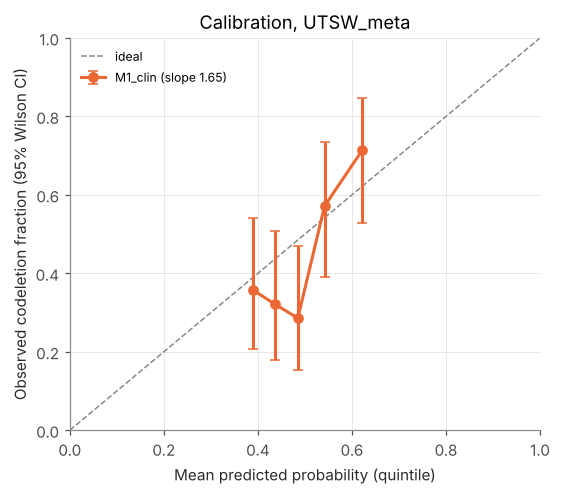

,set,model,slope,intercept_citl,brier
0,UTSW_meta,M1_clin,1.651,-0.186,0.234


In [33]:
def calibration_stats(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); lp = np.log(p / (1 - p))
    slope_m = LogisticRegression(C=1e6, max_iter=5000).fit(lp[:, None], y)
    # calibration-in-the-large: intercept with the logit as a fixed offset (Newton iterations)
    a = 0.0
    for _ in range(50):
        mu = 1 / (1 + np.exp(-(a + lp))); g = (y - mu).sum(); h = (mu * (1 - mu)).sum()
        a += g / h
    return {"slope": float(slope_m.coef_[0, 0]), "intercept_citl": a, "brier": brier_score_loss(y, p)}

cal_set = P["analysis_set"] if P["analysis_set"] in RESULTS["cv"] else "UTSW_meta"
res = RESULTS["cv"][cal_set]
banner() if cal_set == P["analysis_set"] else None
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1, label="ideal")
cal_rows = []
for m, Pm in res.oof.items():
    avg = np.nanmean(Pm, 0)
    cs = calibration_stats(res.y, avg); cal_rows.append({"set": cal_set, "model": m, **cs})
    q = pd.qcut(avg, 5, labels=False, duplicates="drop")
    xs, ys, lo, hi = [], [], [], []
    for qb in np.unique(q):
        sel = q == qb; k, n = int(res.y[sel].sum()), int(sel.sum())
        xs.append(avg[sel].mean()); ys.append(k / n); w = wilson_ci(k, n)
        lo.append(max(0.0, k / n - w[0])); hi.append(max(0.0, w[1] - k / n))   # guard against -1e-17 rounding
    st = model_style(m)
    ax.errorbar(xs, ys, yerr=[lo, hi], fmt="o" + st["ls"], ms=6, capsize=3, color=st["color"],
                label=f"{m} (slope {cs['slope']:.2f})")
ax.set_xlabel("Mean predicted probability (quintile)"); ax.set_ylabel("Observed codeletion fraction (95% Wilson CI)")
ax.set_title(f"Calibration, {cal_set}"); ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.tight_layout(); save_fig(fig, f"15_calibration_{cal_set}"); plt.show()
cal_df = pd.DataFrame(cal_rows); display(cal_df.round(3)); save_table(cal_df, "15_calibration")
RESULTS["calibration"] = cal_df

In [34]:
# Grouped permutation importance (M4, first-repeat test folds)
if P["analysis_set"] in RESULTS["cv"] and RESULTS["cv"][P["analysis_set"]].models_rep0:
    banner()
    res = RESULTS["cv"][P["analysis_set"]]
    rng = np.random.default_rng(CONFIG["seed"] + 9)
    rows = []
    for (f, m), (est, cols, Xte, yte) in res.models_rep0.items():
        if m != "M4":
            continue
        K = int(sum(c.startswith("comp_h") for c in cols))
        groups = {"composition": composition_cols(K), "spatial": spatial_cols(K)}
        base_auc = roc_auc_score(yte, est.predict_proba(Xte.to_numpy(float))[:, 1])
        for gname, gcols in groups.items():
            drops = []
            for _ in range(50):
                Xp = Xte.copy(); perm = rng.permutation(len(Xp))
                Xp[gcols] = Xp[gcols].to_numpy()[perm]
                drops.append(base_auc - roc_auc_score(yte, est.predict_proba(Xp.to_numpy(float))[:, 1]))
            rows.append({"fold": f, "group": gname, "AUROC drop": np.mean(drops)})
    gi = pd.DataFrame(rows).groupby("group")["AUROC drop"].agg(["mean", "std", "count"])
    display(gi.round(4)); save_table(gi, "15_grouped_permutation_importance_M4")
else:
    print("NOT EVALUATED: grouped importance needs the primary M4 model.")

NOT EVALUATED: grouped importance needs the primary M4 model.


In [35]:
# Robustness of the primary comparison (first-repeat folds; each line refits habitats inside every fold)
rob_rows = []
def delta_on_rep1(ids, builder, label):
    strata = (BASE.loc[ids, "cohort"] + "_" + BASE.loc[ids, "label"].astype(str)).value_counts() if len(ids) else pd.Series(dtype=int)
    if len(ids) == 0 or strata.min() < CONFIG["cv"]["n_splits"]:
        rob_rows.append({"variant": label, "n": len(ids), "n_codeleted": int(BASE.loc[ids, "label"].sum()) if len(ids) else 0,
                         "ΔAUROC (fold mean)": np.nan, "NB 95% CI": "NOT RUN: a cohort × label stratum has fewer patients than folds"})
        return
    r = run_cv(ids, ["M3", "M4"], builder, n_repeats=1, thresholds=False, verbose=False)
    if "M4" not in r.oof:
        return
    d = paired_comparison(r, "M4", "M3", label)
    rob_rows.append({"variant": label, "n": len(ids), "n_codeleted": int(BASE.loc[ids, "label"].sum()),
                     "ΔAUROC (fold mean)": d["ΔAUROC (fold mean)"], "NB 95% CI": d["NB 95% CI"],
                     "K per fold": ",".join(str(int(x)) for x in pd.DataFrame(r.fold_info)["K"])})

if P["analysis_set"] in RESULTS["cv"]:
    banner()
    p_ids = ANALYSIS_SETS[P["analysis_set"]][0]
    for k in CONFIG["k_sensitivity"]:
        delta_on_rep1(p_ids, FoldFeatureBuilder(patches, fixed_k=k), f"{P['analysis_set']}: fixed K = {k}")
    for name in ["exclude_histology_discordant", "exclude_grade4"]:
        sub = [p for p in p_ids if p in set(LABEL_SETS[name])]
        delta_on_rep1(sub, builder_img, f"{P['analysis_set']}: {name}")
    if "pooled" in ANALYSIS_SETS:
        delta_on_rep1(ANALYSIS_SETS["pooled"][0], FoldFeatureBuilder(patches, harmonisation="per_cohort_zscore"),
                      "pooled: per-cohort z-score harmonisation (training-only)")
        extra = [p for p in ids_for(["UTSW", "UCSF"], True, primary_only=False)]
        delta_on_rep1(extra, builder_img, "pooled: UCSF relative/unknown resolved by WHO 2021 diagnosis")
    rob = pd.DataFrame(rob_rows); display(rob.round(4)); save_table(rob, "15_robustness_primary_delta")
    RESULTS["robustness"] = rob
else:
    print("NOT EVALUATED: robustness analyses of the primary comparison need habitat features.")

NOT EVALUATED: robustness analyses of the primary comparison need habitat features.


## 16. Results tables and figures

All tables are written to `outputs/tables/` and all figures to `outputs/figures/`. Each figure below is drawn from the result objects computed above; nothing is typed in.

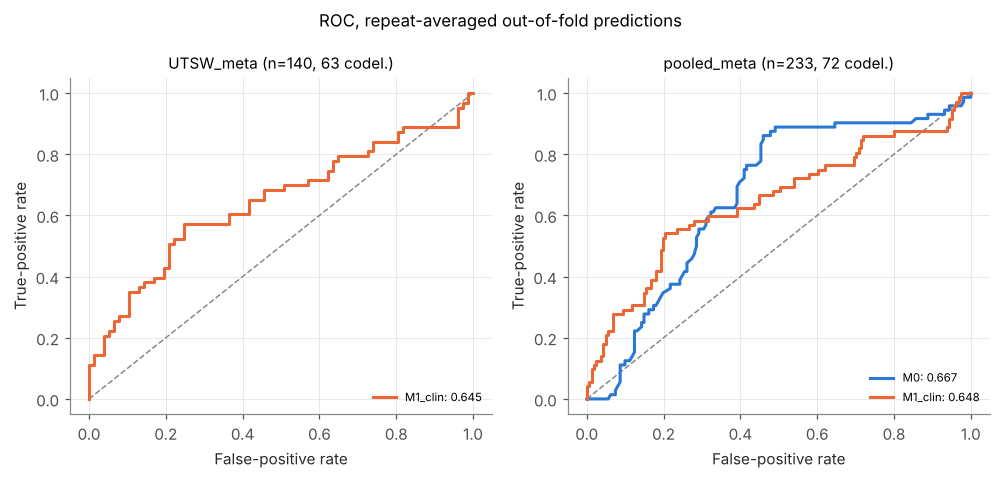

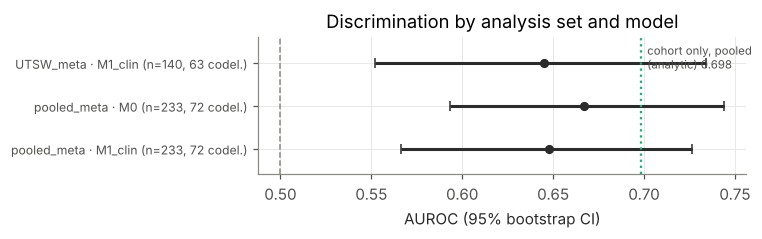

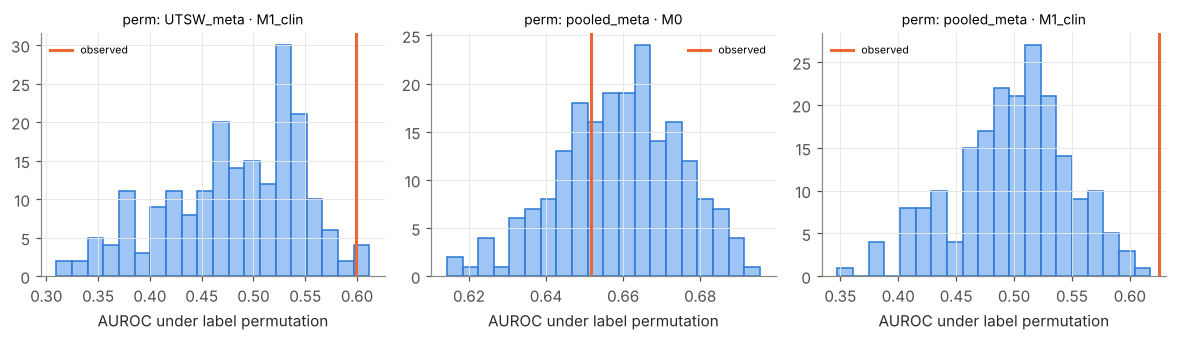

In [36]:
# ROC curves (repeat-averaged out-of-fold predictions) for each analysis set
sets = list(RESULTS["cv"].keys())
fig, axes = plt.subplots(1, len(sets), figsize=(4.6 * len(sets), 4.4), squeeze=False)
for ax, name in zip(axes[0], sets):
    res = RESULTS["cv"][name]
    ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1)
    for m, Pm in res.oof.items():
        avg = np.nanmean(Pm, 0); fpr, tpr, _ = roc_curve(res.y, avg)
        ax.plot(fpr, tpr, **model_style(m), label=f"{m}: {roc_auc_score(res.y, avg):.3f}")
    ax.set_title(f"{name} (n={len(res.y)}, {int(res.y.sum())} codel.)", fontsize=10)
    ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate"); ax.legend(fontsize=7.5, loc="lower right")
fig.suptitle(("SYNTHETIC SMOKE TEST — " if SMOKE else "") + "ROC, repeat-averaged out-of-fold predictions", fontsize=11)
fig.tight_layout(); save_fig(fig, "16_roc_curves"); plt.show()

# Forest plot of AUROC with bootstrap CI
s = RESULTS["summary_table"]
fig, ax = plt.subplots(figsize=(7, 0.36 * len(s) + 1.2))
yl = []
for i, (_, r) in enumerate(s.iloc[::-1].iterrows()):
    ax.errorbar(r["_auc"], i, xerr=[[r["_auc"] - r["_lo"]], [r["_hi"] - r["_auc"]]], fmt="o", color="#2b2b2a", ms=5, capsize=3)
    yl.append(f"{r['set']} · {r['model']} (n={r['n']}, {r['n_codeleted']} codel.)")
ax.axvline(0.5, color="#8a8984", ls="--", lw=1)
if "pooled_meta" in RESULTS["cv"]:
    a0 = SITE_ASSOC["cohort_only_auc"]["auc"]
    ax.axvline(a0, color=COHORT_COL["UCSF"], ls=":", lw=1.5)
    ax.annotate(f"cohort only, pooled\n(analytic) {a0:.3f}", xy=(a0, len(yl) - 0.55), xytext=(4, 0), textcoords="offset points",
                fontsize=7.5, color="#52514e", va="top")
ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl, fontsize=8); ax.set_xlabel("AUROC (95% bootstrap CI)")
ax.set_ylim(-0.6, len(yl) - 0.4)
ax.set_title(("SYNTHETIC SMOKE TEST — " if SMOKE else "") + "Discrimination by analysis set and model")
fig.tight_layout(); save_fig(fig, "16_auroc_forest"); plt.show()

# Null distributions
nulls = {k: v for k, v in RESULTS["nulls"].items()}
if nulls:
    keys = list(nulls)
    fig, axes = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 3.2), squeeze=False)
    for ax, k in zip(axes[0], keys):
        ax.hist(nulls[k], bins=20, color="#9ec5f4", edgecolor="#2a78d6")
        if k == "spatial":
            obs = RESULTS["spatial_null"]["delta_obs_rep1"]; ax.set_xlabel("ΔAUROC M4 − M3 under null")
        else:
            _, sname, m = k.split("|")
            obs = float(RESULTS["label_permutation"].query("set == @sname and model == @m")["observed AUROC (cohort-stratified folds)"].iloc[0])
            ax.set_xlabel("AUROC under label permutation")
        ax.axvline(obs, color=CONFIG["colors"]["codeleted"], lw=2, label="observed")
        ax.set_title(k.replace("labelperm|", "perm: ").replace("|", " · "), fontsize=9); ax.legend(fontsize=7)
    fig.tight_layout(); save_fig(fig, "16_null_distributions"); plt.show()

# Fold-level records for audit
for name, res in RESULTS["cv"].items():
    save_table(res.records, f"16_fold_records_{name}")

## 17. Limitations, failure cases and conclusion

**Known limitations of this design (independent of the results):**

1. **Small number of codeleted UCSF patients.** UCSF contributes few codeleted cases, so UCSF-only and UCSF-trained analyses are uninformative and UTSW→UCSF estimates have wide intervals.
2. **Within-UTSW acquisition heterogeneity.** UTSW spans five vendors and 0.3–3 T over 17 years. The primary analysis removes between-cohort confounding but not within-UTSW scanner effects; field strength is checked against the label in section 6.
3. **Reference standard.** UTSW diagnoses are histology terms from several eras and 1p/19q was tested by NGS or PCR-LOH; UCSF labels include "relative co-deletion". Discordances are flagged and tested in sensitivity analyses, not resolved by assumption.
4. **Segmentation provenance differs** (FeTS automatic or refined vs BraTS ensemble corrected) and the tumour region is the whole abnormality.
5. **Patch scale.** 32 mm patches give a coarse spatial grid; small tumours have few patches. Spatial metrics are defined only with ≥4 patches and are otherwise set to their null value with an indicator.
6. **No untouched external cohort** was available; leave-one-cohort-out is the only transport test.
7. **Repeated-CV inference is approximate.** The Nadeau–Bengio correction reduces but does not remove the dependence between folds.

The cell below writes the conclusion from the executed results only, using the decision rule fixed in section 1.

In [37]:
def conclusion_text():
    L = []
    if SMOKE:
        L.append("**SYNTHETIC SMOKE TEST — these lines describe fake data and verify only that the code runs.**")
    sa = SITE_ASSOC["cohort_only_auc"]
    L.append(f"- Eligible IDH-mutant patients with a resolved 1p/19q label: {len(eligible)} "
             f"(UTSW {int((eligible.cohort == 'UTSW').sum())}, UCSF {int((eligible.cohort == 'UCSF').sum())}); "
             f"codeleted {int(eligible.label.sum())}.")
    L.append(f"- Cohort membership alone gives a pooled AUROC of {fmt_ci(sa['auc'], sa['lo'], sa['hi'])} "
             f"(UTSW vs UCSF odds ratio for codeletion {SITE_ASSOC['odds_ratio_UTSW_vs_UCSF']:.2f}).")
    s = RESULTS["summary_table"]
    for _, r in s[s["set"].isin(["UTSW_meta", "pooled_meta"])].iterrows():
        L.append(f"- Metadata baseline {r['model']} in {r['set']}: AUROC {r['AUROC (repeat-avg OOF, 95% CI)']}.")
    prim = RESULTS.get("primary")
    if prim is None:
        L.append("- **Primary hypothesis H1 (M4 vs M3) was NOT TESTED in this run**: habitat features require the MRI volumes "
                 "and segmentations, which were not available to this execution. No claim about habitat composition or "
                 "spatial arrangement can be made from this run.")
    else:
        sn = RESULTS.get("spatial_null") or {}
        supported = prim["_nb_lo"] > 0 and sn.get("p", 1) < 0.05
        L.append(f"- Primary ΔAUROC (M4 − M3, {CONFIG['primary']['analysis_set']}): {prim['ΔAUROC (fold mean)']:.3f} "
                 f"(Nadeau–Bengio 95% CI {prim['NB 95% CI']}); spatial-arrangement null p = {sn.get('p', float('nan')):.3f}.")
        L.append(f"- By the pre-specified rule, H1 is **{'SUPPORTED' if supported else 'NOT SUPPORTED'}**.")
    lo = RESULTS.get("loco")
    if lo is not None and len(lo):
        for _, r in lo.iterrows():
            if r["status"] == "run":
                L.append(f"- Leave-one-cohort-out {r['train']} → {r['test']}, {r['model']}: AUROC {r['AUROC (95% CI)']}.")
            else:
                L.append(f"- Leave-one-cohort-out {r['train']} → {r['test']}: {r['status']}.")
    for n in RESULTS["notes"]:
        L.append(f"- Note: {n}")
    return "\n".join(L)

CONCLUSION = conclusion_text()
display(Markdown(CONCLUSION))
(OUT / "conclusion.md").write_text(CONCLUSION)

- Eligible IDH-mutant patients with a resolved 1p/19q label: 233 (UTSW 140, UCSF 93); codeleted 72.
- Cohort membership alone gives a pooled AUROC of 0.698 (0.643–0.752) (UTSW vs UCSF odds ratio for codeletion 7.57).
- Metadata baseline M1_clin in UTSW_meta: AUROC 0.645 (0.552–0.734).
- Metadata baseline M0 in pooled_meta: AUROC 0.667 (0.593–0.744).
- Metadata baseline M1_clin in pooled_meta: AUROC 0.648 (0.566–0.726).
- **Primary hypothesis H1 (M4 vs M3) was NOT TESTED in this run**: habitat features require the MRI volumes and segmentations, which were not available to this execution. No claim about habitat composition or spatial arrangement can be made from this run.
- Leave-one-cohort-out UTSW (n=140, 63 codel.) → UCSF (n=93, 9 codel.), M1_clin: AUROC 0.644 (0.402–0.845).
- Leave-one-cohort-out UCSF → UTSW: NOT RUN: 9 codeleted training patients < 20.
- Note: Imaging-based models (M1 with volume, M2–M5) NOT EVALUATED: no habitat-evaluable imaging. Required: the four structural NIfTI volumes and the tumour segmentation for each eligible patient.
- Note: PRIMARY COMPARISON NOT EVALUATED: M4 vs M3 in the UTSW set needs habitat features, which require the MRI volumes and segmentations (see section 7).

1220

## 18. Reproducibility manifest and final study checklist

The manifest records software versions, the full configuration, SHA-256 hashes of the input metadata, the patient flow and the status of every automated check. To regenerate everything: set the three environment variables (section 3), install `requirements.txt`, and run all cells top to bottom (`jupyter nbconvert --to notebook --execute`). Feature extraction is cached per patient and invalidated automatically when an extraction setting changes.

In [38]:
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    if isinstance(o, Path): return str(o)
    if isinstance(o, (set, tuple)): return list(o)
    return str(o)

manual_checklist = [
    ("Primary comparison pre-specified before imaging results", "PASS (section 1; decided from metadata only)"),
    ("Habitat model refitted inside every training fold", "PASS (asserted per fold)" if IMAGING_AVAILABLE else "NOT RUN (no imaging)"),
    ("Shape features excluded from habitat clustering", "PASS (habitat_columns asserts)" if IMAGING_AVAILABLE else "NOT RUN (no imaging)"),
    ("Spatial metrics composition-adjusted (within-patient permutation null)", "PASS (by construction)" if IMAGING_AVAILABLE else "NOT RUN (no imaging)"),
    ("Thresholds chosen on training folds only", "PASS (train_only_threshold)"),
    ("Label-permutation test reruns the full learning procedure on label-independent folds", "PASS"),
    ("Leave-one-cohort-out run only when training events are sufficient", "PASS"),
    ("External untouched cohort", "NOT AVAILABLE"),
]
checks_df = pd.concat([pd.DataFrame(CHECKS).T.rename(columns={"status": "result"}),
                       pd.DataFrame(manual_checklist, columns=["check", "result"]).set_index("check")])
display(checks_df)
save_table(checks_df, "18_checklist")

manifest = {
    "notebook": "Habitat_1p19q_IDHmut_v3.ipynb", "run_finished": time.strftime("%Y-%m-%d %H:%M:%S"),
    "imaging_mode": CONFIG["imaging_mode"], "environment": ENV, "config": CONFIG, "input_sha256": INPUT_HASHES,
    "patient_flow_metadata": flow_df.to_dict(orient="records"),
    "original_cohort_hypothesis": ORIGINAL_COHORT_HYPOTHESIS,
    "imaging_available": bool(IMAGING_AVAILABLE), "n_habitat_evaluable": len(evaluable_ids),
    "extraction_fingerprint": config_fingerprint(), "checks": CHECKS,
    "outputs": sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file() and "per_patient" not in str(p)
                      and "smoke_test_data" not in str(p)),
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1, default=jsonable))
counts = pd.Series([v["status"] for v in CHECKS.values()]).value_counts().to_dict()
print(f"Manifest written to {OUT / 'manifest.json'} | automated checks: {counts}")
banner()

,result,detail
UTSW source IDs unique,PASS,625 unique of 625
UCSF source IDs unique,PASS,501 unique of 501
Every UCSF follow-up has exactly one baseline row,PASS,6 follow-up rows
UCSF canonical patient IDs unique after removing follow-ups,PASS,495 patients
No patient ID shared across cohorts,PASS,
No IDH-wildtype tumour labelled codeleted,PASS,0 cases
No grade-4 tumour labelled codeleted,PASS,0 cases
Eligible cohort is IDH-mutant only,PASS,233 patients
Cohort–label association quantified,PASS,cohort-only AUROC 0.698
Imaging available for at least one eligible patient,NOT AVAILABLE,imaging sections will report NOT EVALUATED


Manifest written to /home/claude/work/outputs_real/manifest.json | automated checks: {'PASS': 13, 'NOT AVAILABLE': 1}
